# 9.5 Sigma Sweep — Additive batch conditioning (decipher_*_add)

Same sweep structure as `9.4 sigma-sweep-2.ipynb`, but using the additive-batch-conditioning
variants (`decipher_vz_add`, `decipher_vz2_add`, `decipher_mf_add`) in place of
`decipher_vz`, `decipher_vz2`, `decipher_mf`. These variants replace concatenation of `v`
(or `x`) with the batch embedding by a per-batch additive shift in z-space
(`self.batch_shift`), matching how the synthetic data's batch effect is actually generated
(`z_mean = latent_t @ w_bio + shift`). `Base Decipher` (unmodified) stays in as the
reference point.

Runs `seeds = [0, 1, 2, 3, 4]` and `shift_sigmas = [0.1, 0.25, 0.5, 0.75, 1.0, 2.0, 5.0]` in
a single combined sweep (no cross-machine CSV merge needed, unlike 9.4).

Writes to the same locations `simulated_data_pipeline_aug1.py` always writes to:
`shift_sigma_sweep/<MMDD>/trained/` for trained `.h5ad` files and
`shift_sigma_sweep/<MMDD>/figs/` for reconstruction diagnostic figures (both are automatic
side effects of `train_and_compute_rho_r2`, no extra code needed here). `<MMDD>` is
whatever today's date is when the sweep cell actually runs.

## Import pipeline module

In [1]:
import sys
sys.path.insert(0, "/Users/alanxie/CodingProjects/Columbia/Azizi Lab/Spatial Nut Carcinoma/decipher-bc-methods/Data/Simulated Data/Simulated Data Generation")

import os
import numpy as np
import pandas as pd
from datetime import datetime

from simulated_data_pipeline_aug1 import train_and_compute_rho_r2

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/torch/cuda/__init__.py:54: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


## Run sweep

Epoch 228 (batch 22/22) | | train elbo: 325.84 (last epoch: 324.93) | val ll: 333.47:  23%|██▎       | 228/1000 [00:54<03:03,  4.20it/s]2026-08-06 16:53:49,550 | INFO : Early stopping has been triggered.
2026-08-06 16:53:49,553 | INFO : Added `.obsm['decipher_v']`: the Decipher v space.
2026-08-06 16:53:49,553 | INFO : Added `.obsm['decipher_z']`: the Decipher z space.
2026-08-06 16:53:49,553 | INFO : Saving decipher model with run_id 2026-08-06-16-53-49-mechanical-coffee-yeast.


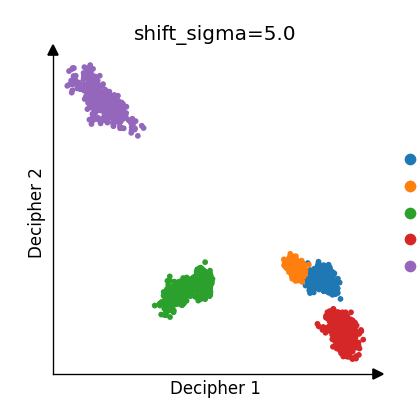

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
... storing 'shift' as categorical
... storing 'batch' as categorical
2026-08-06 16:53:50,239 | INFO : Clustering cells using scanpy Leiden algorithm.
2026-08-06 16:53:50,240 | INFO : Step 1: Computing neighbors with `sc.pp.neighbors`, with the representation decipher_z.
2026-08-06 16:53:50,256 | INFO : Step 2: Computing clusters with `sc.tl.leiden`, and resolution 1.0.
2026-08-06 16:53:50,447 | INFO : Added `.obs['decipher_clusters']`: the cluster labels.
/Users/alanxie/CodingProjects/Columbia/Azizi Lab/Spatial Nut Carcinoma/decipher-bc-methods/Data/Simulated Data/Simulated Data Generation/simulated_data_pipeline_aug1.py:510: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass ob

,model,n_z_dims,shift_sigma,seed,decipher_seed,rho,trained_h5ad,r2_overall,r2_per_gene_median,error
0,Decipher-VZ-Add,3,0.1,0,1,0.857148,/Users/alanxie/CodingProjects/Columbia/Azizi L...,0.763299,0.484001,None
1,Decipher-VZ-Add,3,0.1,1,1,0.923123,/Users/alanxie/CodingProjects/Columbia/Azizi L...,0.780946,0.530793,None
2,Decipher-VZ-Add,3,0.1,2,1,0.880855,/Users/alanxie/CodingProjects/Columbia/Azizi L...,0.747574,0.432858,None
3,Decipher-VZ-Add,3,0.1,3,1,0.992205,/Users/alanxie/CodingProjects/Columbia/Azizi L...,0.905267,0.778391,None
4,Decipher-VZ-Add,3,0.1,4,1,0.977576,/Users/alanxie/CodingProjects/Columbia/Azizi L...,0.812664,0.641203,None
...,...,...,...,...,...,...,...,...,...,...
135,Base Decipher,3,5.0,0,1,0.474330,/Users/alanxie/CodingProjects/Columbia/Azizi L...,0.952813,0.944216,None
136,Base Decipher,3,5.0,1,1,0.712986,/Users/alanxie/CodingProjects/Columbia/Azizi L...,0.952729,0.949412,None
137,Base Decipher,3,5.0,2,1,0.586126,/Users/alanxie/CodingProjects/Columbia/Azizi L...,0.960495,0.946613,None
138,Base Decipher,3,5.0,3,1,0.817049,/Users/alanxie/CodingProjects/Columbia/Azizi L...,0.962429,0.947614,None


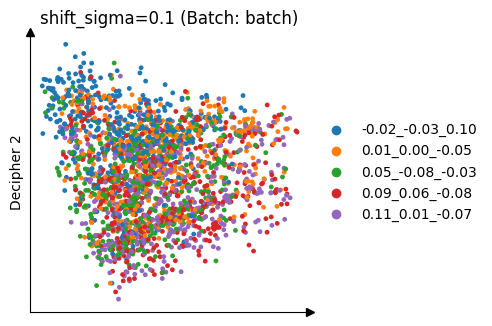

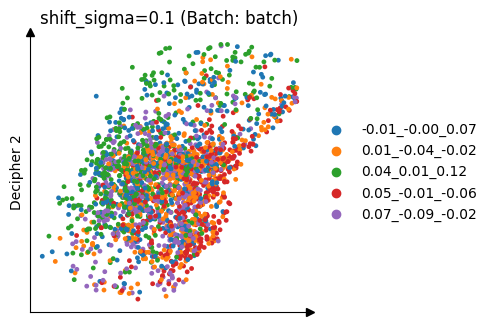

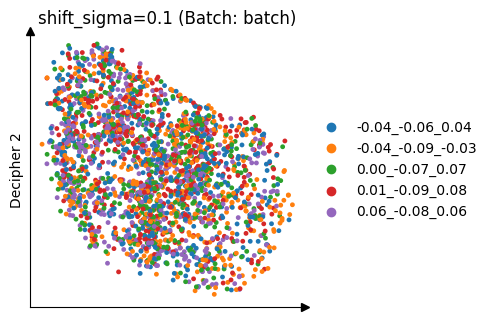

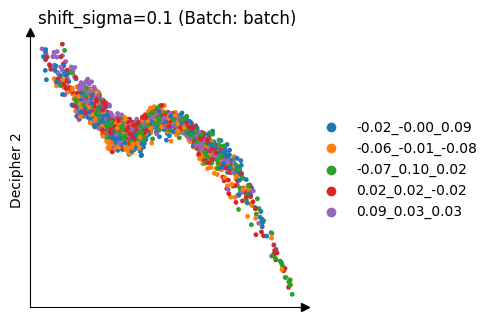

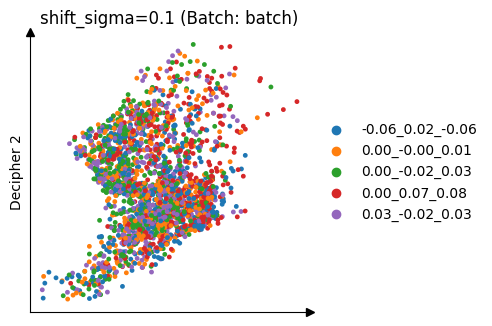

...

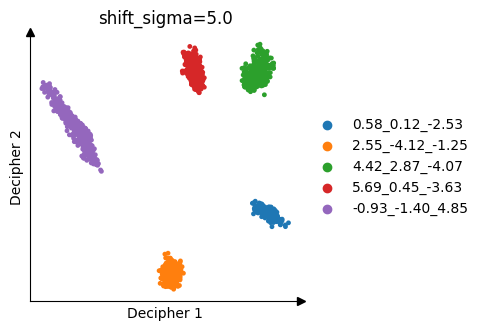

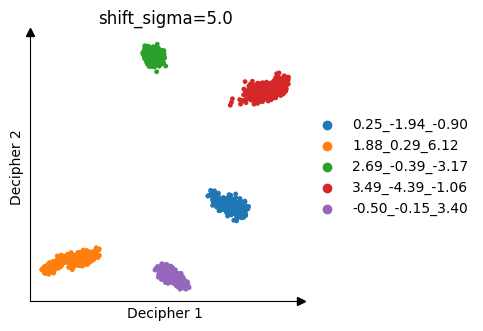

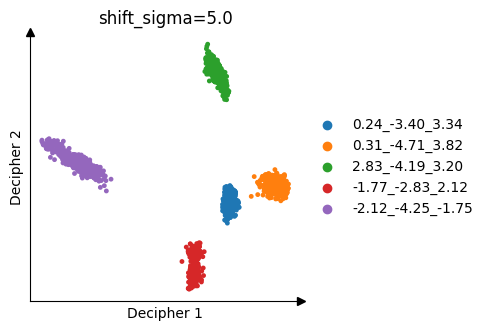

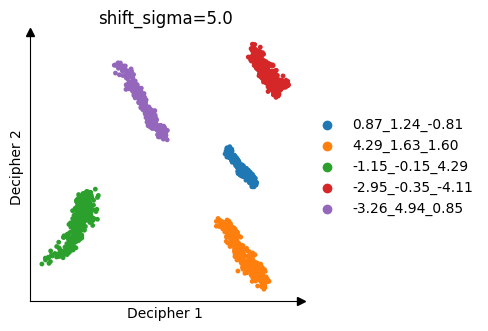

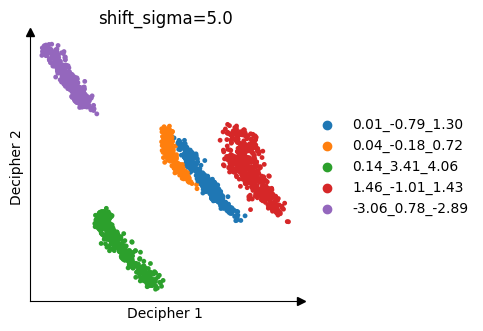

In [2]:
# ---- sweep ----
# shift distribution is MVN(0, shift_sigma^2 * I) in n_z_dims
shift_sigmas = [0.1, 0.25, 0.5, 0.75, 1.0, 2.0, 5.0]
seeds = [0, 1, 2, 3, 4]
decipher_seeds = [1]  # one decipher_seed
n_z_dims = 3
n_samples = 500
n_genes = 200
biological_sigma = 0.1
models = {
    "Decipher-VZ-Add": "decipher_vz_add",
    "Decipher-VZ2-Add": "decipher_vz2_add",
    "Decipher-MF-Add": "decipher_mf_add",
    "Base Decipher": "decipher",
}
colors = {
    "Decipher-VZ-Add": "#00897B",
    "Decipher-VZ2-Add": "#7B1FA2",
    "Decipher-MF-Add": "#AD1457",
    "Base Decipher": "#C62828",
}

pipeline_dir = "/Users/alanxie/CodingProjects/Columbia/Azizi Lab/Spatial Nut Carcinoma/decipher-bc-methods/Data/Simulated Data/Simulated Data Generation"
today = datetime.now().strftime("%m%d")
log_dir = os.path.join(pipeline_dir, "..", "Simulated Adata", "shift_sigma_sweep", today)
os.makedirs(log_dir, exist_ok=True)
csv_path = os.path.join(log_dir, f"sweep_log_{shift_sigmas}_{seeds}.csv")

run_log = []
for name, model in models.items():
    for shift_sigma in shift_sigmas:
        for sd in seeds:
            for decipher_seed in decipher_seeds:
                record = {
                    "model": name, "n_z_dims": n_z_dims,
                    "shift_sigma": shift_sigma, "seed": sd,
                    "decipher_seed": decipher_seed,
                }
                try:
                    rho, trained_path, r2_overall, r2_per_gene_median, _ = train_and_compute_rho_r2(
                        model, decipher_seed,
                        shift_sigma=shift_sigma,
                        n_samples=n_samples,
                        n_genes=n_genes,
                        biological_sigma=biological_sigma,
                        seed=sd,
                        n_z_dims=n_z_dims,
                    )
                    record.update({
                        "rho": rho, "trained_h5ad": trained_path,
                        "r2_overall": r2_overall,
                        "r2_per_gene_median": r2_per_gene_median,
                        "error": None,
                    })
                except Exception as e:
                    print(f"[{name}] n_z_dims={n_z_dims} shift_sigma={shift_sigma} "
                          f"seed={sd} decipher_seed={decipher_seed} "
                          f"failed: {type(e).__name__}: {e}")
                    record.update({
                        "rho": np.nan, "trained_h5ad": None,
                        "r2_overall": np.nan, "r2_per_gene_median": np.nan,
                        "error": f"{type(e).__name__}: {e}",
                    })
                run_log.append(record)
                pd.DataFrame(run_log).to_csv(csv_path, index=False)

run_log_df = pd.DataFrame(run_log)
run_log_df

## Correlation Plot

2026-08-06 17:12:00,230 | INFO : Substituting symbol N from STIXNonUnicode
2026-08-06 17:12:00,249 | INFO : Substituting symbol N from STIXNonUnicode
2026-08-06 17:12:00,303 | INFO : Substituting symbol N from STIXNonUnicode
2026-08-06 17:12:00,327 | INFO : Substituting symbol N from STIXNonUnicode


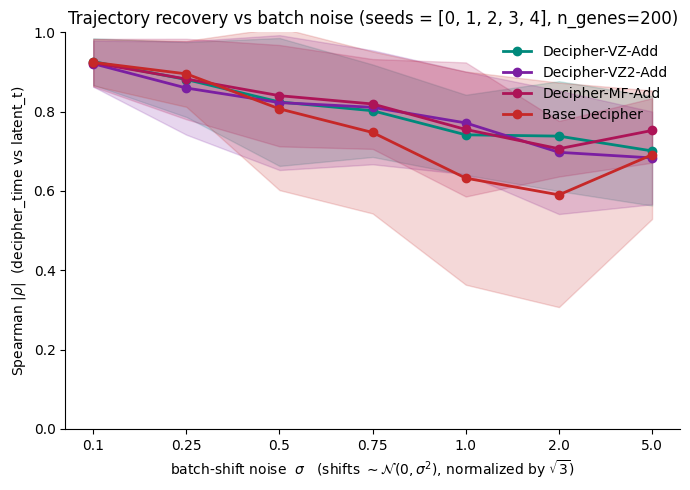

In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime

pipeline_dir = "/Users/alanxie/CodingProjects/Columbia/Azizi Lab/Spatial Nut Carcinoma/decipher-bc-methods/Data/Simulated Data/Simulated Data Generation"
today = datetime.now().strftime("%m%d")
log_dir = os.path.join(pipeline_dir, "..", "Simulated Adata", "shift_sigma_sweep", today)
trained_dir = os.path.join(log_dir, "trained")
models = {
    "Decipher-VZ-Add": "decipher_vz_add",
    "Decipher-VZ2-Add": "decipher_vz2_add",
    "Decipher-MF-Add": "decipher_mf_add",
    "Base Decipher": "decipher",
}
colors = {
    "Decipher-VZ-Add": "#00897B",
    "Decipher-VZ2-Add": "#7B1FA2",
    "Decipher-MF-Add": "#AD1457",
    "Base Decipher": "#C62828",
}

shift_sigmas = [0.1, 0.25, 0.5, 0.75, 1.0, 2.0, 5.0]
seeds = [0, 1, 2, 3, 4]
run_log_df = pd.read_csv(os.path.join(log_dir, f"sweep_log_{shift_sigmas}_{seeds}.csv"))
run_log_df = run_log_df[run_log_df["error"].isna()].copy()

sigmas_sorted = sorted(run_log_df["shift_sigma"].unique())
x_pos = np.arange(len(sigmas_sorted))  # evenly spaced positions, one per sigma tested

fig, ax = plt.subplots(figsize=(7, 5))
for name in models:
    sub = run_log_df[run_log_df["model"] == name]
    stats = sub.groupby("shift_sigma")["rho"].agg(["mean", "std"]).reindex(sigmas_sorted)
    mean = stats["mean"].to_numpy()
    sd_ = stats["std"].to_numpy()
    ax.plot(x_pos, mean, marker="o", color=colors[name], label=name, linewidth=2)
    ax.fill_between(x_pos, mean - sd_, mean + sd_, color=colors[name], alpha=0.18)

ax.set_xticks(x_pos)
ax.set_xticklabels([str(s) for s in sigmas_sorted])
ax.set_xlabel(r"batch-shift noise  $\sigma$   (shifts $\sim \mathcal{N}(0,\sigma^2)$, normalized by $\sqrt{3}$)")
ax.set_ylabel(r"Spearman $|\rho|$  (decipher_time vs latent_t)")
ax.set_title(f"Trajectory recovery vs batch noise (seeds = {seeds}, n_genes=200)")
ax.set_ylim(0, 1); ax.axhline(0, color="0.8", lw=0.8)
ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig("sigma_vs_correlation_9.5.png", dpi=200)
plt.show()

In [4]:
rho_summary = run_log_df.groupby("shift_sigma")["rho"].agg(["mean", "std"]).reindex(sigmas_sorted).round(3)
rho_summary

,mean,std
shift_sigma,,
0.10,0.924,0.054
0.25,0.879,0.093
0.50,0.824,0.155
0.75,0.795,0.140
1.00,0.725,0.173
2.00,0.683,0.174
5.00,0.707,0.121


## V-space integration metrics (scib_metrics)

The mentor's check: Z-space should separate batch (silhouette high), V-space should *not* (batches should mix). iLISI, graph connectivity, and (rescaled) batch silhouette are all oriented so **higher = better integration** here.

In [5]:
import scanpy as sc

def compute_integration_metrics(adata,
                                v_key="decipher_v", batch_key="batch", t_key="latent_t",
                                n_neighbors=30, n_bins=5):
    from scib_metrics.nearest_neighbors import pynndescent
    from scib_metrics import ilisi_knn, graph_connectivity, silhouette_batch
    import pandas as pd
    import numpy as np
    adata.obs["latent_t_bin"] = pd.qcut(
        adata.obs[t_key], q=n_bins, labels=False
    ).astype("category")
    neigh = pynndescent(adata.obsm[v_key], n_neighbors=n_neighbors)
    batches = adata.obs[batch_key].cat.codes.to_numpy()
    bins    = adata.obs["latent_t_bin"].cat.codes.to_numpy()
    return {
        "ilisi": ilisi_knn(neigh, batches, scale=True),
        "graph_conn": graph_connectivity(neigh, labels=bins),
        "sil_batch": silhouette_batch(adata.obsm[v_key], labels=bins, batch=batches, rescale=True),
    }

In [6]:
# Only rows that trained successfully have a trained_h5ad to read.
ok_df = run_log_df[run_log_df["error"].isna()].copy()

v_records = []
for _, row in ok_df.iterrows():
    adata = sc.read_h5ad(row["trained_h5ad"])
    m = compute_integration_metrics(adata, v_key="decipher_v", batch_key="batch", t_key="latent_t",
                                     n_neighbors=30, n_bins=5)
    m.update({"model": row["model"], "shift_sigma": row["shift_sigma"], "seed": row["seed"]})
    v_records.append(m)

v_results_df = pd.DataFrame(v_records)
v_results_df.to_csv(os.path.join(log_dir, "v_space_integration_metrics_9.5.csv"), index=False)
v_results_df

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
INFO:2026-08-06 17:12:07,539:jax._src.xla_bridge:822: Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: dlopen(libtpu.so, 0x0001): tried: 'libtpu.so' (no such file), '/System/Volumes/Preboot/Cryptexes/OSlibtpu.so' (no such file), '/Users/alanxie/miniconda3/envs/decipher_env/bin/../lib/libtpu.so' (no such file), '/usr/lib/libtpu.so' (no such file, not in dyld cache), 'libtpu.so' (no such file)
2026-08-06 17:12:07,539 | INFO : Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: dlopen(libtpu.so, 0x0001): tried: 'libtpu.so' (no such file), '/System/Volumes/Preboot/Cryptexes/OSlibtpu.so' (no such file), '/Users/alanxie/miniconda3/envs/decipher_env/bin/../lib/libtpu.so' (no such file), '/usr/lib/libtpu.so' (no suc

,ilisi,graph_conn,sil_batch,model,shift_sigma,seed
0,0.469207,0.9564,0.814610,Decipher-VZ-Add,0.1,0
1,0.460936,0.9764,0.813183,Decipher-VZ-Add,0.1,1
2,0.519573,0.9636,0.898431,Decipher-VZ-Add,0.1,2
3,0.528662,0.9696,0.832913,Decipher-VZ-Add,0.1,3
4,0.514457,0.9772,0.860227,Decipher-VZ-Add,0.1,4
...,...,...,...,...,...,...
135,0.000000,0.2152,0.102951,Base Decipher,5.0,0
136,0.000000,0.2148,0.073661,Base Decipher,5.0,1
137,0.000000,0.2056,0.121926,Base Decipher,5.0,2
138,0.000000,0.2216,0.069910,Base Decipher,5.0,3


### V-space metrics vs sigma

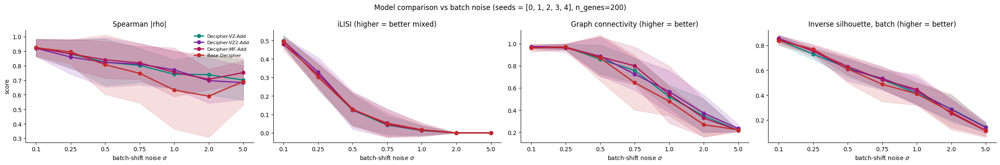

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(24, 4))
panels = [
    ("rho", "Spearman |rho|", run_log_df),
    ("ilisi", "iLISI (higher = better mixed)", v_results_df),
    ("graph_conn", "Graph connectivity (higher = better)", v_results_df),
    ("sil_batch", "Inverse silhouette, batch (higher = better)", v_results_df),
]
for ax, (col, title, df) in zip(axes, panels):
    for name in models:
        sub = df[df["model"] == name]
        stats = sub.groupby("shift_sigma")[col].agg(["mean", "std"]).reindex(sigmas_sorted)
        mean = stats["mean"].to_numpy()
        sd_ = stats["std"].to_numpy()
        ax.plot(x_pos, mean, marker="o", color=colors[name], label=name, linewidth=2)
        ax.fill_between(x_pos, mean - sd_, mean + sd_, color=colors[name], alpha=0.15)
    ax.set_xticks(x_pos)
    ax.set_xticklabels([str(s) for s in sigmas_sorted])
    ax.set_xlabel(r"batch-shift noise $\sigma$")
    ax.set_title(title)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("score")
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle(f"Model comparison vs batch noise (seeds = [0, 1, 2, 3, 4], n_genes=200)")
fig.tight_layout()
fig.savefig("v_space_metrics_vs_sigma_9.5.png", dpi=200)
plt.show()

In [8]:
v_summary = (v_results_df
    .groupby(["model", "shift_sigma"])[["ilisi", "graph_conn", "sil_batch"]]
    .agg(["mean", "std"]).round(3))
v_summary

ilisi        graph_conn        sil_batch       
                               mean    std       mean    std      mean    std
model            shift_sigma                                                 
Base Decipher    0.10         0.495  0.028      0.960  0.036     0.838  0.040
                 0.25         0.302  0.066      0.971  0.023     0.769  0.038
                 0.50         0.127  0.091      0.870  0.208     0.611  0.113
                 0.75         0.052  0.076      0.647  0.247     0.487  0.141
                 1.00         0.017  0.038      0.479  0.131     0.410  0.091
                 2.00         0.000  0.000      0.268  0.113     0.263  0.143
                 5.00         0.000  0.000      0.222  0.017     0.115  0.055
Decipher-MF-Add  0.10         0.480  0.031      0.965  0.019     0.851  0.028
                 0.25         0.316  0.070      0.962  0.040     0.755  0.024
                 0.50         0.129  0.084      0.881  0.177     0.630  0.068
                 0.75         0.045  0.063      0.800  0.170     0.524  0.076
                 1.00         0.014  0.025      0.539  0.258     0.445  0.119
                 2.00         0.000  0.000      0.328  0.167     0.252  0.112
                 5.00         0.000  0.000      0.217  0.005     0.112  0.045
Decipher-VZ-Add  0.10         0.499  0.031      0.969  0.009     0.844  0.036
                 0.25         0.303  0.069      0.969  0.025     0.730  0.043
                 0.50         0.123  0.086      0.858  0.131     0.617  0.071
                 0.75         0.042  0.049      0.757  0.113     0.525  0.078
                 1.00         0.012  0.027      0.521  0.103     0.412  0.083
                 2.00         0.000  0.000      0.347  0.154     0.288  0.108
                 5.00         0.000  0.000      0.217  0.004     0.141  0.037
Decipher-VZ2-Add 0.10         0.496  0.022      0.973  0.016     0.857  0.027
                 0.25         0.329  0.078      0.967  0.026     0.754  0.046
                 0.50         0.123  0.102      0.885  0.175     0.609  0.097
                 0.75         0.053  0.077      0.724  0.146     0.534  0.093
                 1.00         0.016  0.033      0.566  0.190     0.428  0.110
                 2.00         0.000  0.000      0.371  0.166     0.284  0.086
                 5.00         0.000  0.000      0.234  0.036     0.138  0.045

## Per-sigma, per-model detail: Z-space, V-space, X-space

Pools all 5 seeds `[0, 1, 2, 3, 4]` the same way as the Correlation Plot / V-space
integration metrics sections above. Each section below picks one representative seed
(`seed_for_detail`) per (model, sigma) for the illustrative plots, matching 9.4's convention
-- plotting all 5 seeds here would multiply every figure by 5.

In [9]:
import os
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_score
from datetime import datetime

pipeline_dir = "/Users/alanxie/CodingProjects/Columbia/Azizi Lab/Spatial Nut Carcinoma/decipher-bc-methods/Data/Simulated Data/Simulated Data Generation"
today = datetime.now().strftime("%m%d")
log_dir = os.path.join(pipeline_dir, "..", "Simulated Adata", "shift_sigma_sweep", today)
trained_dir = os.path.join(log_dir, "trained")
models = {
    "Decipher-VZ-Add": "decipher_vz_add",
    "Decipher-VZ2-Add": "decipher_vz2_add",
    "Decipher-MF-Add": "decipher_mf_add",
    "Base Decipher": "decipher",
}
colors = {
    "Decipher-VZ-Add": "#00897B",
    "Decipher-VZ2-Add": "#7B1FA2",
    "Decipher-MF-Add": "#AD1457",
    "Base Decipher": "#C62828",
}

shift_sigmas = [0.1, 0.25, 0.5, 0.75, 1.0, 2.0, 5.0]
seeds = [0, 1, 2, 3, 4]
run_log_df = pd.read_csv(os.path.join(log_dir, f"sweep_log_{shift_sigmas}_{seeds}.csv"))
run_log_df = run_log_df[run_log_df["error"].isna()].copy()

def load_run(df, shift_sigma, model_name, seed=None):
    sub = df[(df["shift_sigma"] == shift_sigma) & (df["model"] == model_name)]
    if seed is not None:
        sub = sub[sub["seed"] == seed]
    row = sub.iloc[0]
    return row, sc.read_h5ad(row["trained_h5ad"])

latent_z_cols = ["latent_z0", "latent_z1", "latent_z2"]
model_names = list(models.keys())
seed_for_detail = 0

## Z-space: ground truth vs. learned decipher_z

In [10]:
def plot_z_space(shift_sigma, seed=seed_for_detail):
    for model_name in model_names:
        row, adata = load_run(run_log_df, shift_sigma, model_name, seed=seed)
        batch_labels = adata.obs["batch"].astype(str)

        sil_ground_truth = silhouette_score(
            adata.obs[latent_z_cols].values, batch_labels,
            sample_size=min(5000, adata.n_obs), random_state=42,
        )
        sil_learned = silhouette_score(
            adata.obsm["decipher_z"], batch_labels,
            sample_size=min(5000, adata.n_obs), random_state=42,
        )
        print(f"{model_name}  sigma={shift_sigma}  seed={seed}  ground truth z silhouette (by batch) = {sil_ground_truth:.4f}")
        print(f"{model_name}  sigma={shift_sigma}  seed={seed}  learned decipher_z silhouette (by batch) = {sil_learned:.4f}")

        adata.obsm["latent_z"] = adata.obs[latent_z_cols].values
        sc.pp.neighbors(adata, use_rep="latent_z", key_added="latent_z_neighbors", random_state=42)
        sc.tl.umap(adata, neighbors_key="latent_z_neighbors", random_state=42)
        adata.obsm["latent_z_umap"] = adata.obsm["X_umap"]

        sc.pp.neighbors(adata, use_rep="decipher_z", random_state=42)
        sc.tl.umap(adata, random_state=42)
        adata.obsm["decipher_z_umap"] = adata.obsm["X_umap"]

        fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))
        sc.pl.embedding(adata, basis="latent_z_umap", color="batch",
                        ax=axes[0], show=False, title=f"Ground truth z (3D), UMAP ({model_name}, sigma={shift_sigma})")
        sc.pl.embedding(adata, basis="decipher_z_umap", color="batch",
                        ax=axes[1], show=False, title=f"Learned decipher_z, UMAP ({model_name}, sigma={shift_sigma})")
        plt.tight_layout()
        plt.show()

### Sigma = 0.1

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Decipher-VZ-Add  sigma=0.1  seed=0  ground truth z silhouette (by batch) = -0.0378
Decipher-VZ-Add  sigma=0.1  seed=0  learned decipher_z silhouette (by batch) = -0.0580


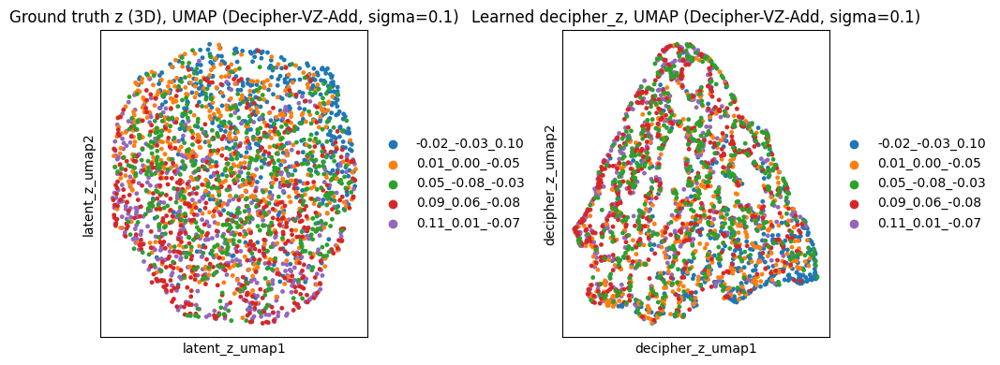

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Decipher-VZ2-Add  sigma=0.1  seed=0  ground truth z silhouette (by batch) = -0.0378
Decipher-VZ2-Add  sigma=0.1  seed=0  learned decipher_z silhouette (by batch) = -0.0527


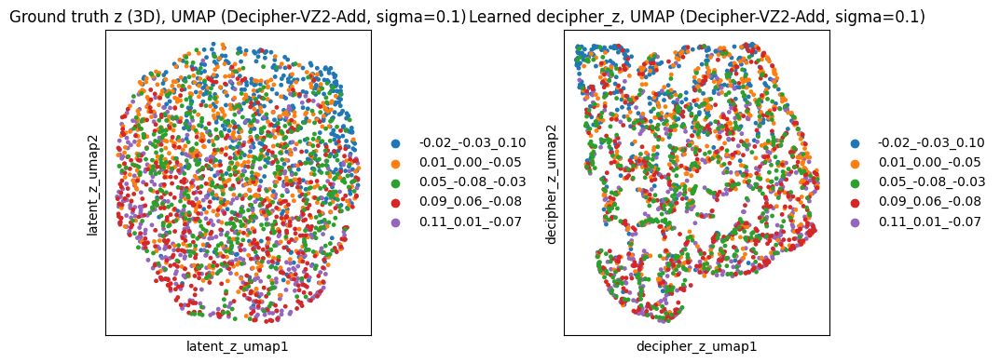

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Decipher-MF-Add  sigma=0.1  seed=0  ground truth z silhouette (by batch) = -0.0378
Decipher-MF-Add  sigma=0.1  seed=0  learned decipher_z silhouette (by batch) = -0.0504


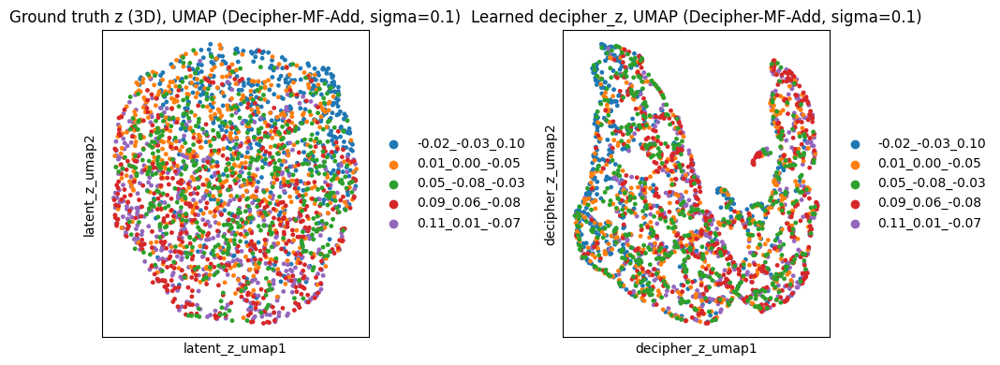

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Base Decipher  sigma=0.1  seed=0  ground truth z silhouette (by batch) = -0.0378
Base Decipher  sigma=0.1  seed=0  learned decipher_z silhouette (by batch) = -0.0755


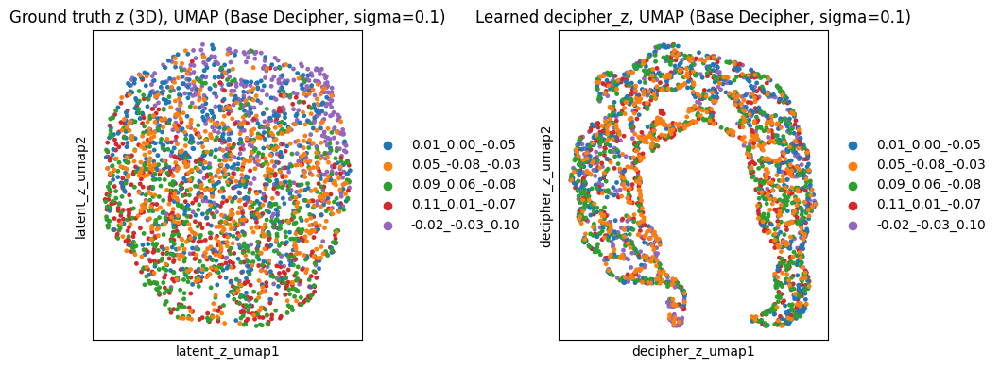

In [11]:
plot_z_space(0.1)

### Sigma = 0.25

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Decipher-VZ-Add  sigma=0.25  seed=0  ground truth z silhouette (by batch) = 0.0776
Decipher-VZ-Add  sigma=0.25  seed=0  learned decipher_z silhouette (by batch) = 0.0251


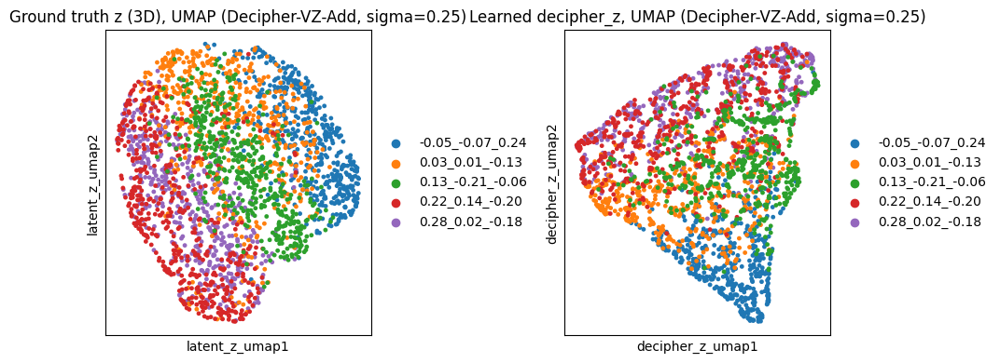

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Decipher-VZ2-Add  sigma=0.25  seed=0  ground truth z silhouette (by batch) = 0.0776
Decipher-VZ2-Add  sigma=0.25  seed=0  learned decipher_z silhouette (by batch) = 0.0026


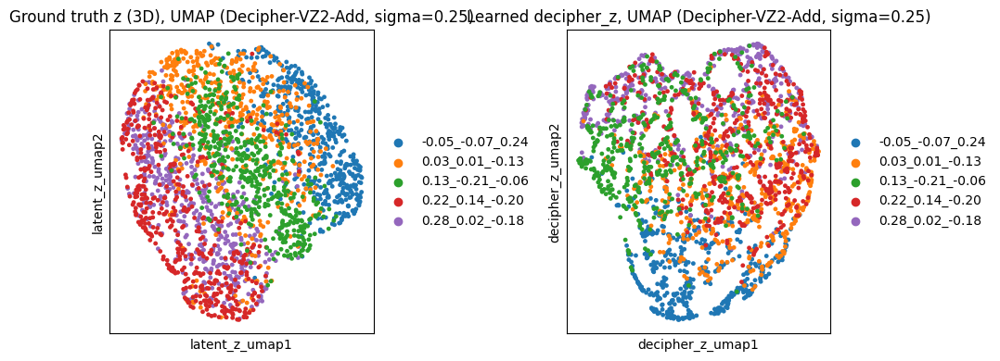

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Decipher-MF-Add  sigma=0.25  seed=0  ground truth z silhouette (by batch) = 0.0776
Decipher-MF-Add  sigma=0.25  seed=0  learned decipher_z silhouette (by batch) = 0.0185


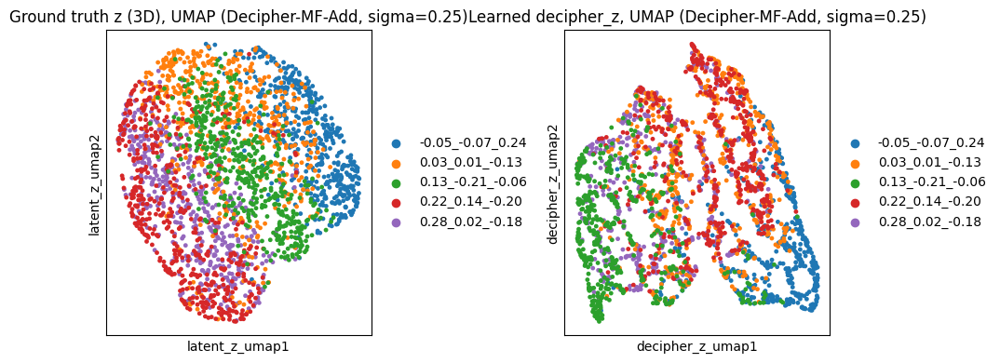

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Base Decipher  sigma=0.25  seed=0  ground truth z silhouette (by batch) = 0.0776
Base Decipher  sigma=0.25  seed=0  learned decipher_z silhouette (by batch) = 0.0007


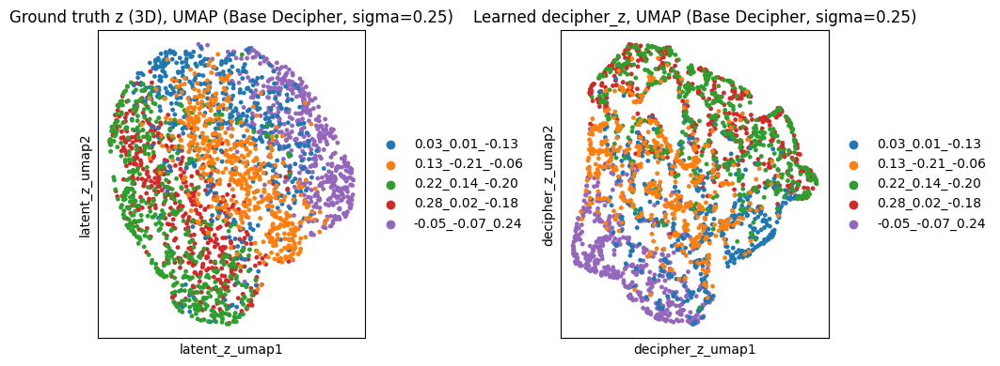

In [12]:
plot_z_space(0.25)

### Sigma = 0.5

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Decipher-VZ-Add  sigma=0.5  seed=0  ground truth z silhouette (by batch) = 0.3318
Decipher-VZ-Add  sigma=0.5  seed=0  learned decipher_z silhouette (by batch) = 0.3235


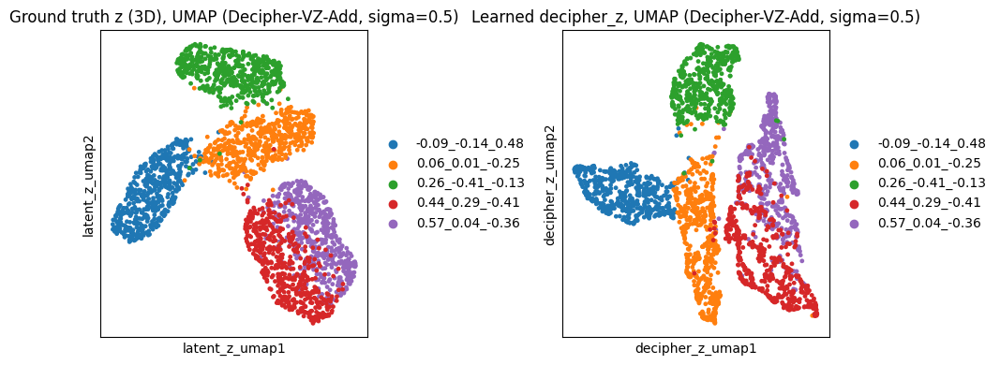

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Decipher-VZ2-Add  sigma=0.5  seed=0  ground truth z silhouette (by batch) = 0.3318
Decipher-VZ2-Add  sigma=0.5  seed=0  learned decipher_z silhouette (by batch) = 0.3235


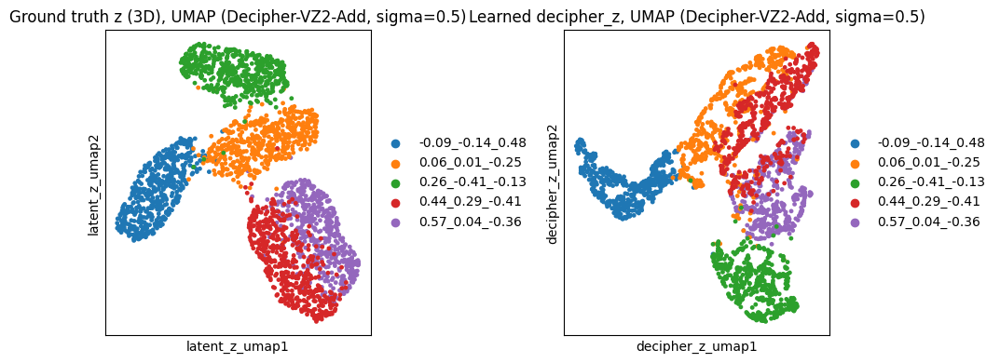

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Decipher-MF-Add  sigma=0.5  seed=0  ground truth z silhouette (by batch) = 0.3318
Decipher-MF-Add  sigma=0.5  seed=0  learned decipher_z silhouette (by batch) = 0.1859


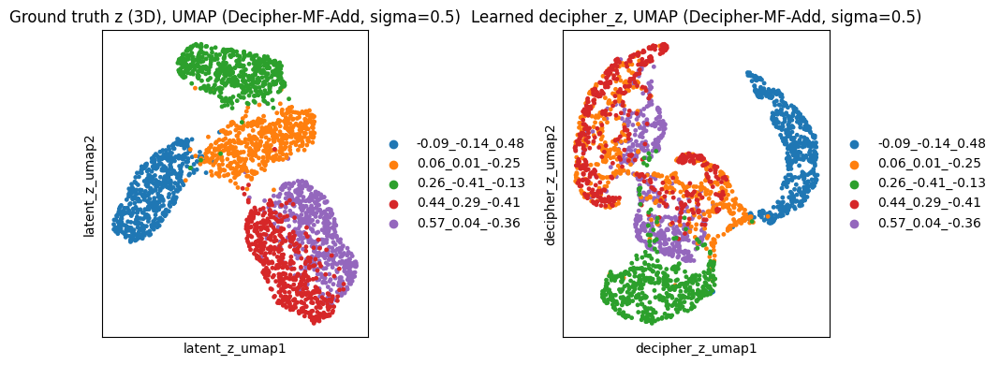

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Base Decipher  sigma=0.5  seed=0  ground truth z silhouette (by batch) = 0.3318
Base Decipher  sigma=0.5  seed=0  learned decipher_z silhouette (by batch) = 0.3958


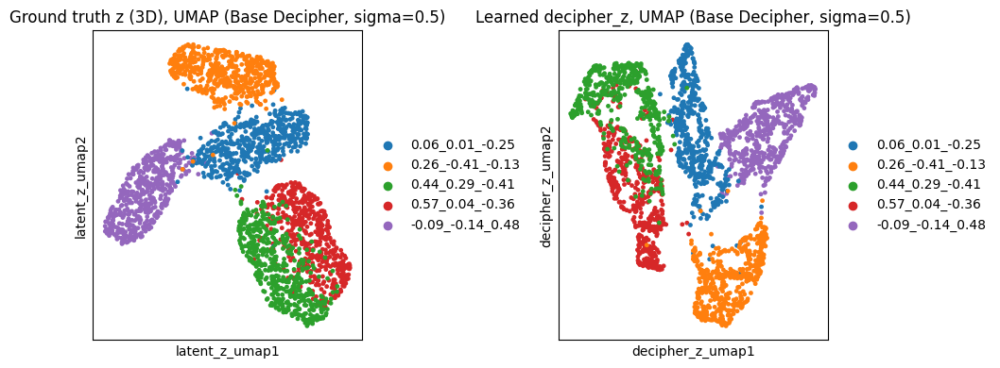

In [13]:
plot_z_space(0.5)

### Sigma = 0.75

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Decipher-VZ-Add  sigma=0.75  seed=0  ground truth z silhouette (by batch) = 0.4983
Decipher-VZ-Add  sigma=0.75  seed=0  learned decipher_z silhouette (by batch) = 0.4659


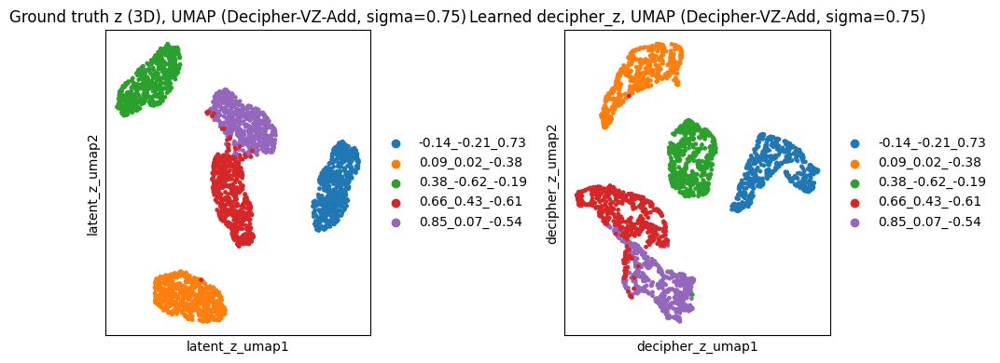

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Decipher-VZ2-Add  sigma=0.75  seed=0  ground truth z silhouette (by batch) = 0.4983
Decipher-VZ2-Add  sigma=0.75  seed=0  learned decipher_z silhouette (by batch) = 0.3836


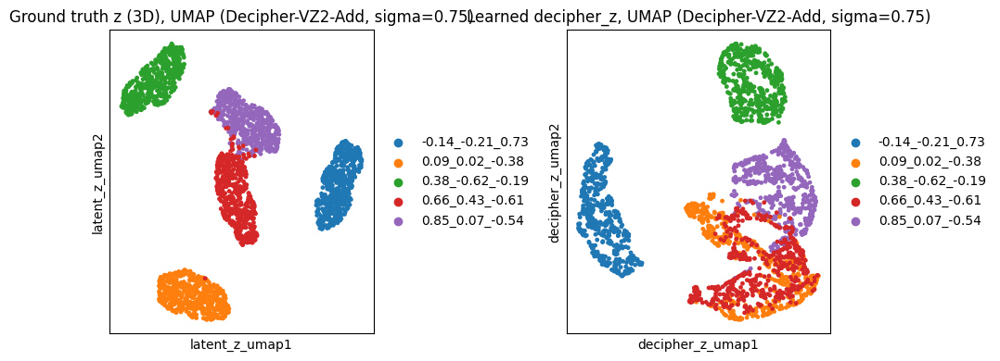

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Decipher-MF-Add  sigma=0.75  seed=0  ground truth z silhouette (by batch) = 0.4983
Decipher-MF-Add  sigma=0.75  seed=0  learned decipher_z silhouette (by batch) = 0.2662


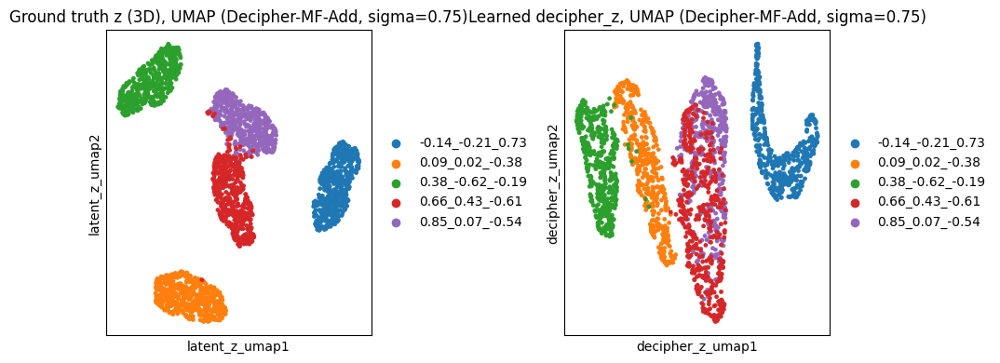

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Base Decipher  sigma=0.75  seed=0  ground truth z silhouette (by batch) = 0.4983
Base Decipher  sigma=0.75  seed=0  learned decipher_z silhouette (by batch) = 0.5402


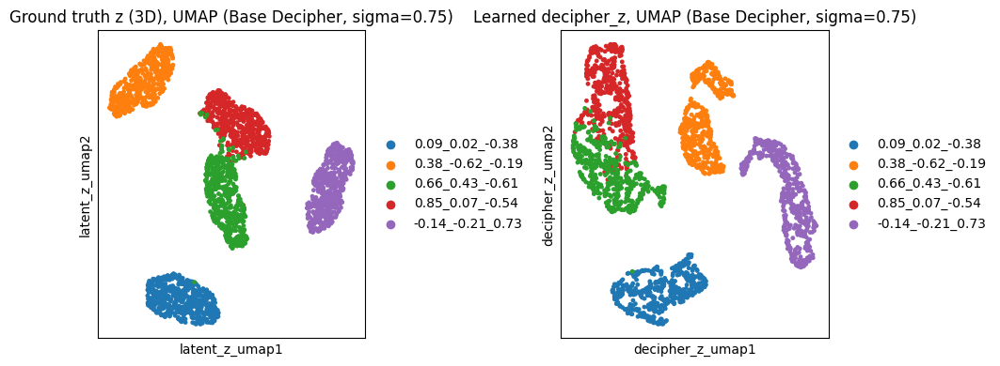

In [14]:
plot_z_space(0.75)

### Sigma = 1.0

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Decipher-VZ-Add  sigma=1.0  seed=0  ground truth z silhouette (by batch) = 0.6037
Decipher-VZ-Add  sigma=1.0  seed=0  learned decipher_z silhouette (by batch) = 0.5674


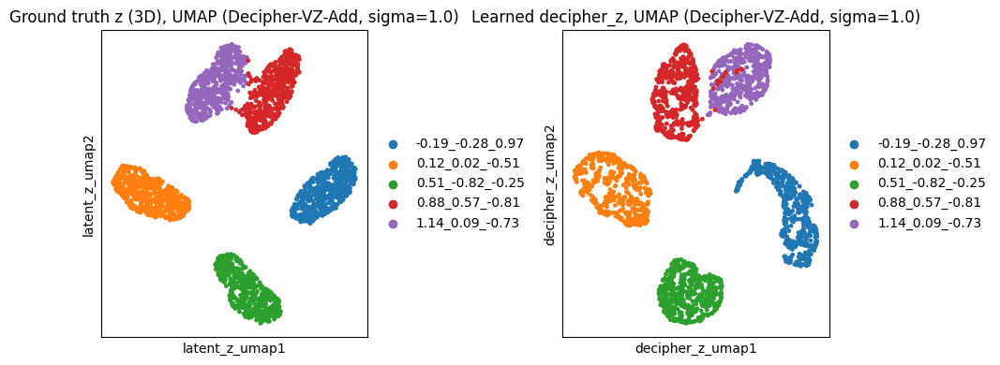

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Decipher-VZ2-Add  sigma=1.0  seed=0  ground truth z silhouette (by batch) = 0.6037
Decipher-VZ2-Add  sigma=1.0  seed=0  learned decipher_z silhouette (by batch) = 0.5379


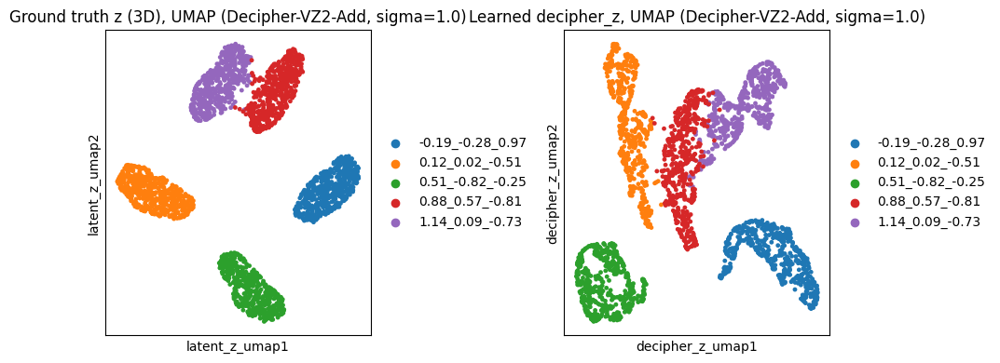

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Decipher-MF-Add  sigma=1.0  seed=0  ground truth z silhouette (by batch) = 0.6037
Decipher-MF-Add  sigma=1.0  seed=0  learned decipher_z silhouette (by batch) = 0.4714


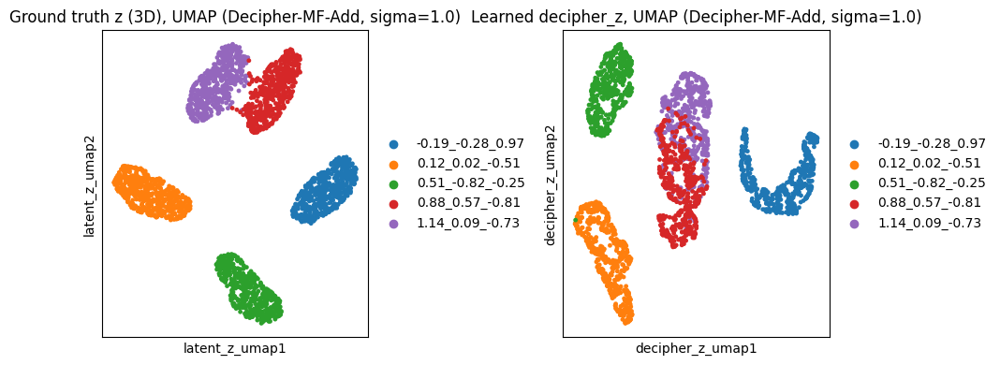

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Base Decipher  sigma=1.0  seed=0  ground truth z silhouette (by batch) = 0.6037
Base Decipher  sigma=1.0  seed=0  learned decipher_z silhouette (by batch) = 0.6251


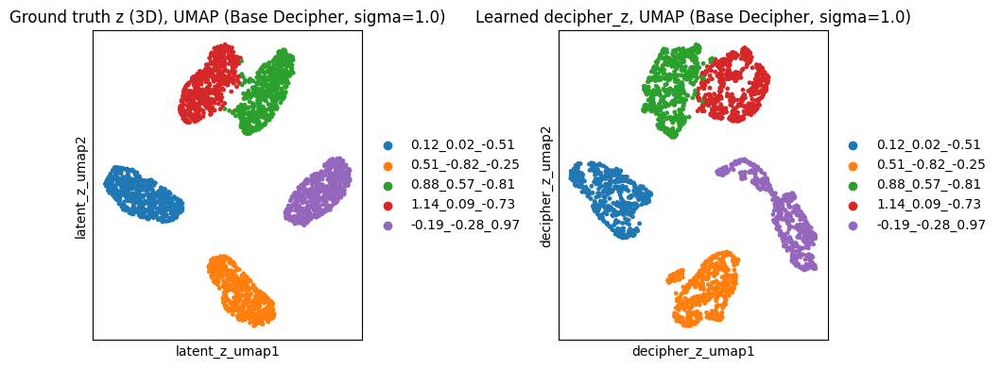

In [15]:
plot_z_space(1.0)

### Sigma = 2.0

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Decipher-VZ-Add  sigma=2.0  seed=0  ground truth z silhouette (by batch) = 0.7918
Decipher-VZ-Add  sigma=2.0  seed=0  learned decipher_z silhouette (by batch) = 0.7906


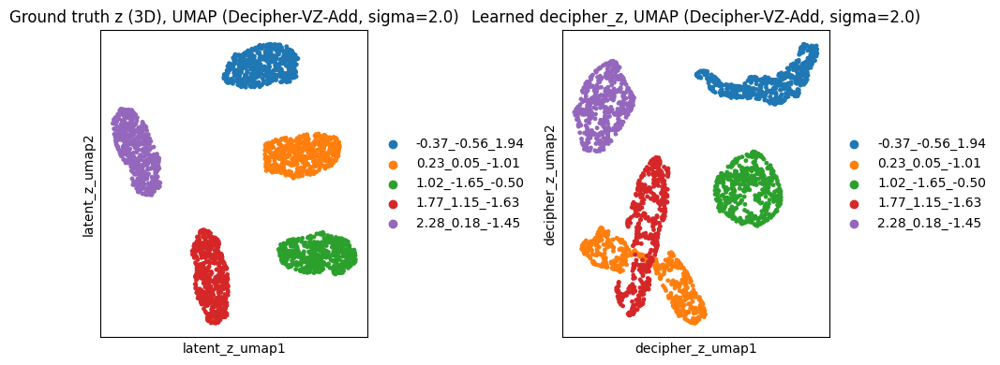

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Decipher-VZ2-Add  sigma=2.0  seed=0  ground truth z silhouette (by batch) = 0.7918
Decipher-VZ2-Add  sigma=2.0  seed=0  learned decipher_z silhouette (by batch) = 0.7311


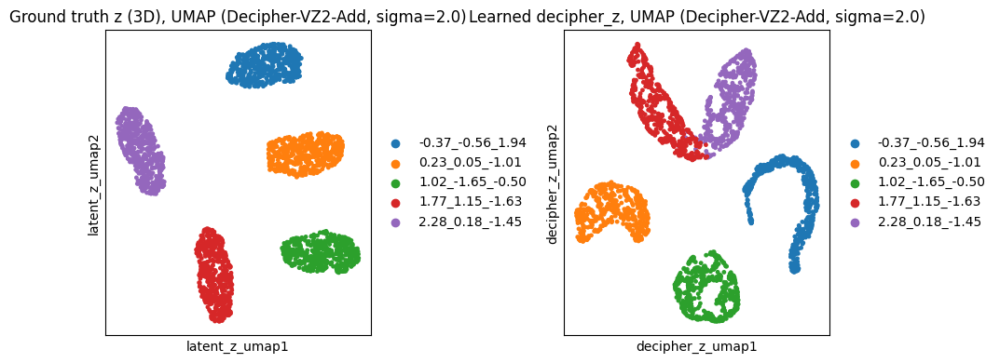

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Decipher-MF-Add  sigma=2.0  seed=0  ground truth z silhouette (by batch) = 0.7918
Decipher-MF-Add  sigma=2.0  seed=0  learned decipher_z silhouette (by batch) = 0.7618


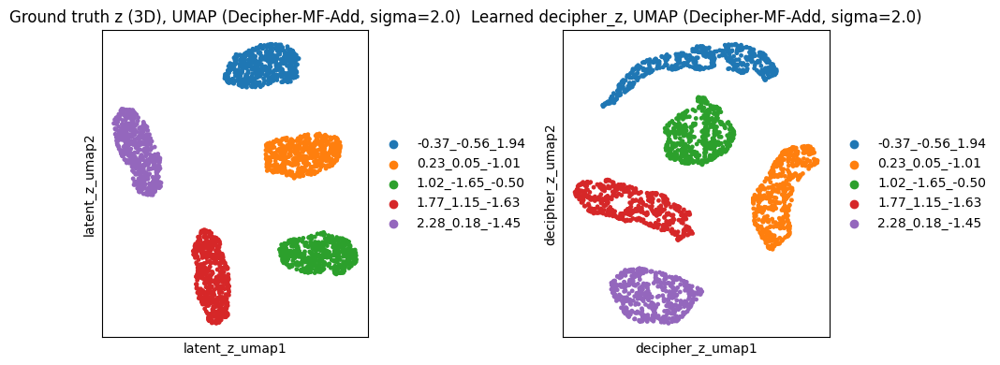

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Base Decipher  sigma=2.0  seed=0  ground truth z silhouette (by batch) = 0.7918
Base Decipher  sigma=2.0  seed=0  learned decipher_z silhouette (by batch) = 0.7771


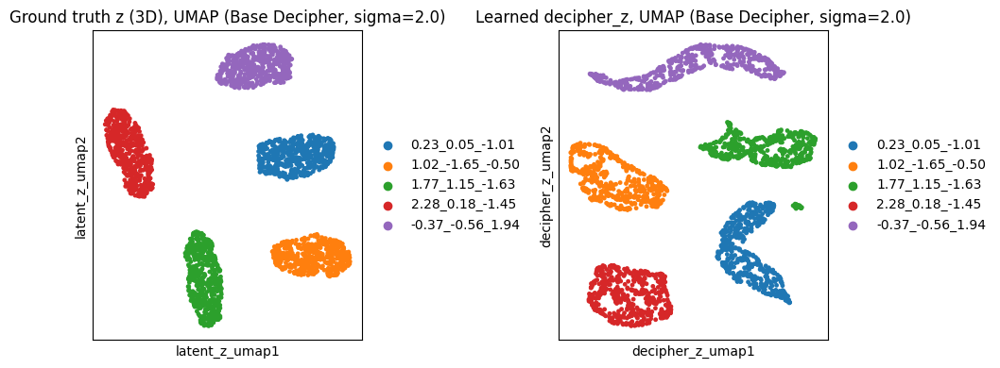

In [16]:
plot_z_space(2.0)

### Sigma = 5.0

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Decipher-VZ-Add  sigma=5.0  seed=0  ground truth z silhouette (by batch) = 0.9160
Decipher-VZ-Add  sigma=5.0  seed=0  learned decipher_z silhouette (by batch) = 0.8905


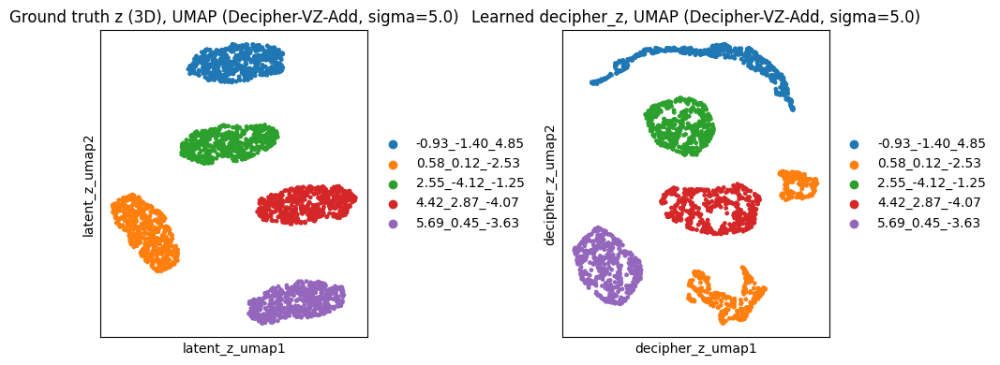

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Decipher-VZ2-Add  sigma=5.0  seed=0  ground truth z silhouette (by batch) = 0.9160
Decipher-VZ2-Add  sigma=5.0  seed=0  learned decipher_z silhouette (by batch) = 0.8773


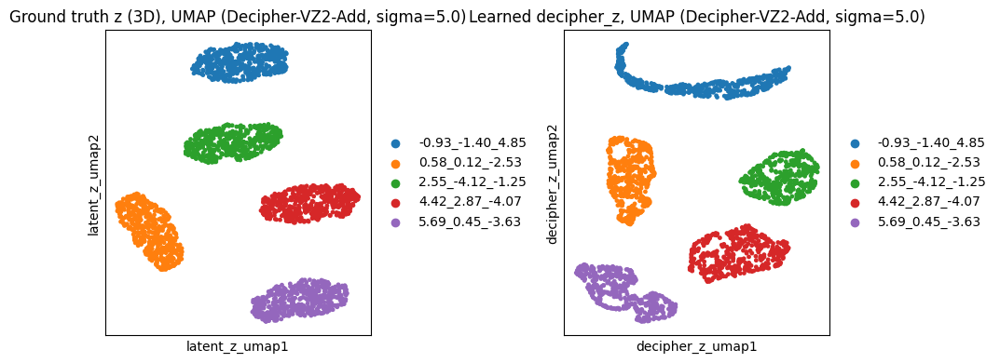

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Decipher-MF-Add  sigma=5.0  seed=0  ground truth z silhouette (by batch) = 0.9160
Decipher-MF-Add  sigma=5.0  seed=0  learned decipher_z silhouette (by batch) = 0.8601


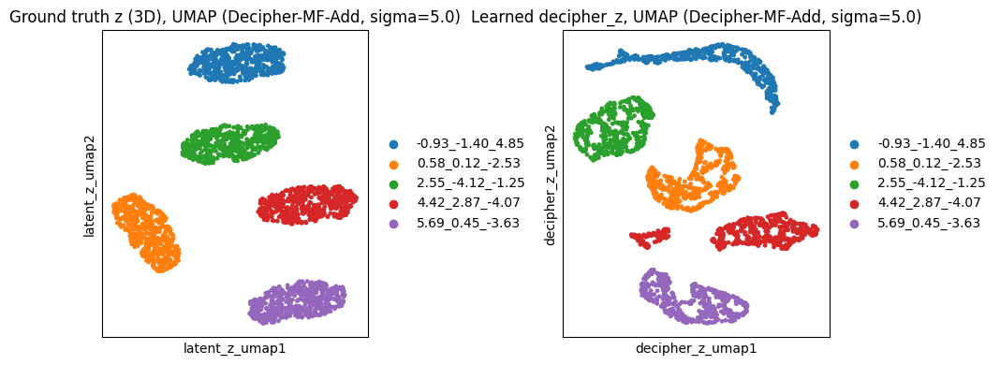

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Base Decipher  sigma=5.0  seed=0  ground truth z silhouette (by batch) = 0.9160
Base Decipher  sigma=5.0  seed=0  learned decipher_z silhouette (by batch) = 0.8899


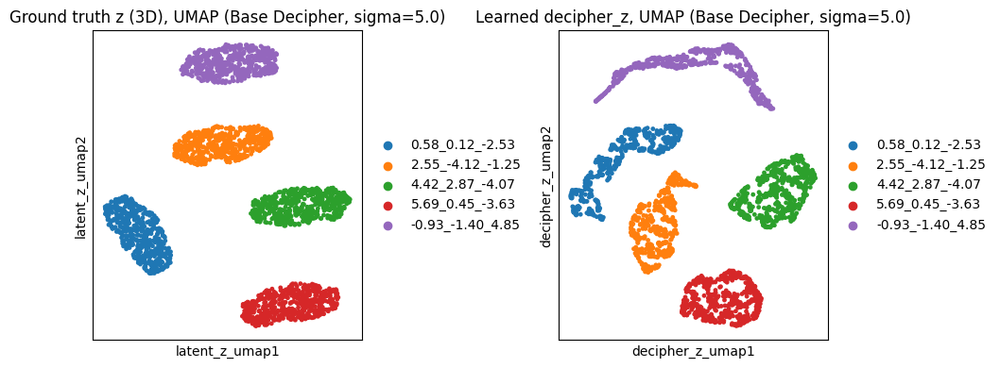

In [17]:
plot_z_space(5.0)

## V-space: colored by batch, latent pseudotime, learned pseudotime

In [18]:
def plot_v_space(shift_sigma, seed=seed_for_detail):
    for model_name in model_names:
        row, adata = load_run(run_log_df, shift_sigma, model_name, seed=seed)
        sc.pl.embedding(adata, basis="decipher_v", color=["batch", "latent_t", "decipher_time"])
        print(f"{model_name}, sigma={shift_sigma}, seed={row['seed']}, rho = {row['rho']:.4f}")

### Sigma = 0.1

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


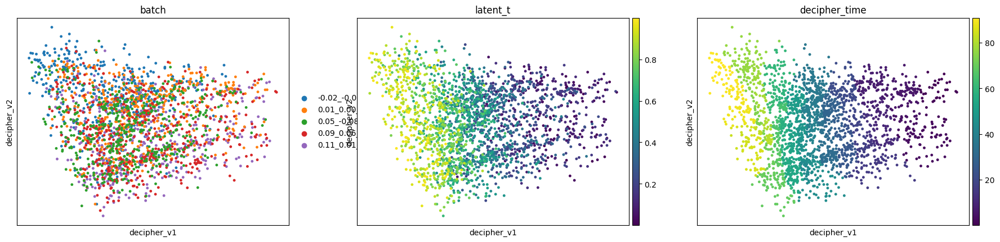

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Decipher-VZ-Add, sigma=0.1, seed=0, rho = 0.8571


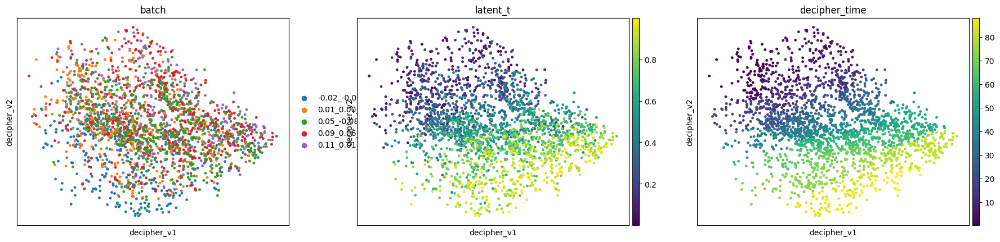

Decipher-VZ2-Add, sigma=0.1, seed=0, rho = 0.8573


/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


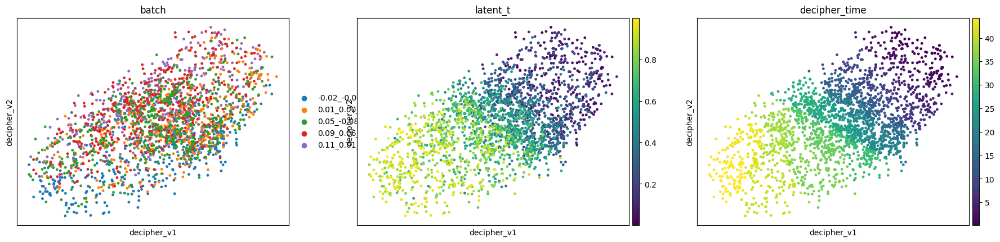

Decipher-MF-Add, sigma=0.1, seed=0, rho = 0.8650


/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


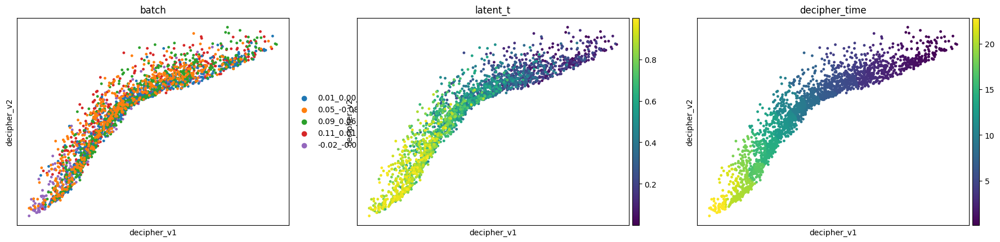

Base Decipher, sigma=0.1, seed=0, rho = 0.8603


In [19]:
plot_v_space(0.1)

### Sigma = 0.25

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


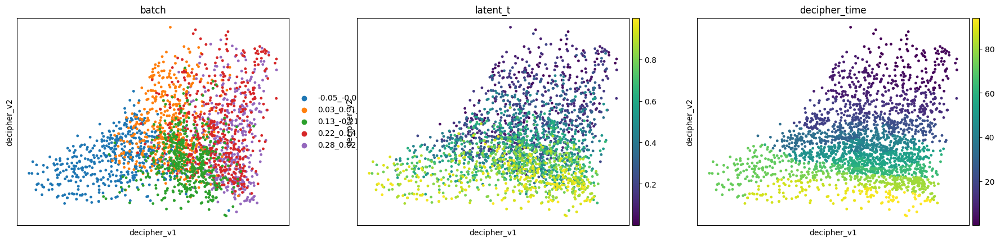

Decipher-VZ-Add, sigma=0.25, seed=0, rho = 0.7416


/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


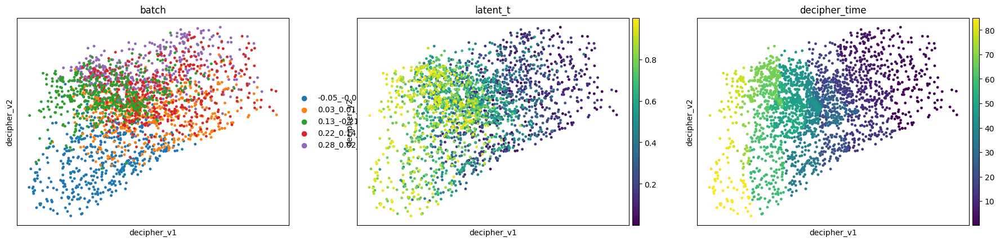

Decipher-VZ2-Add, sigma=0.25, seed=0, rho = 0.6983


/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


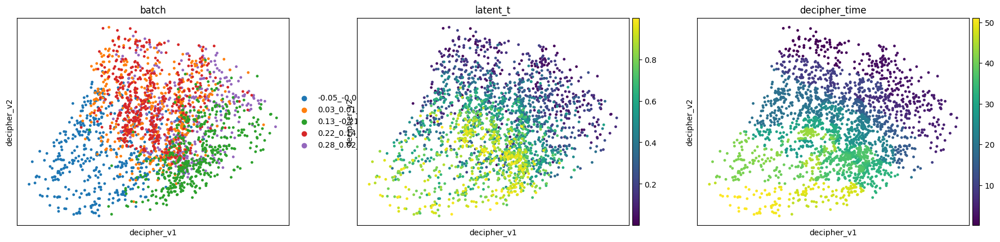

Decipher-MF-Add, sigma=0.25, seed=0, rho = 0.7377


/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


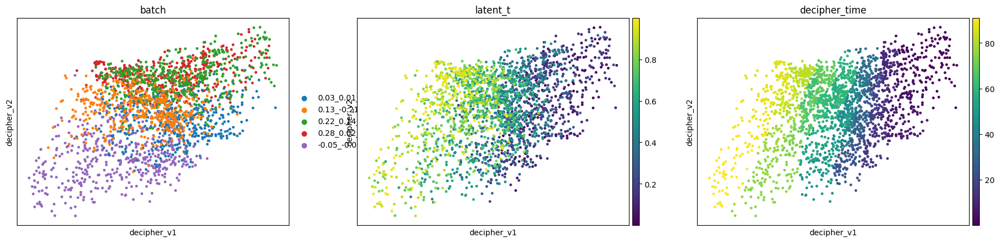

Base Decipher, sigma=0.25, seed=0, rho = 0.7797


In [20]:
plot_v_space(0.25)

### Sigma = 0.5

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


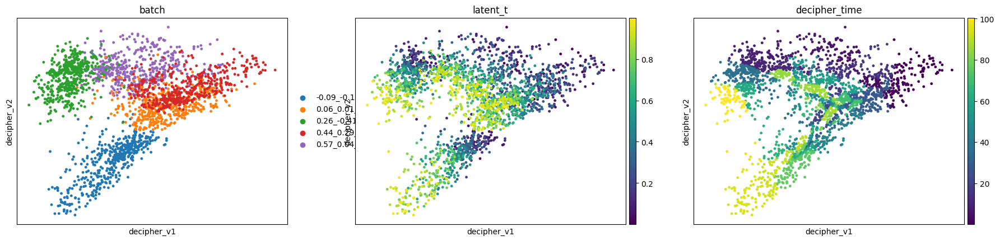

Decipher-VZ-Add, sigma=0.5, seed=0, rho = 0.5593


/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


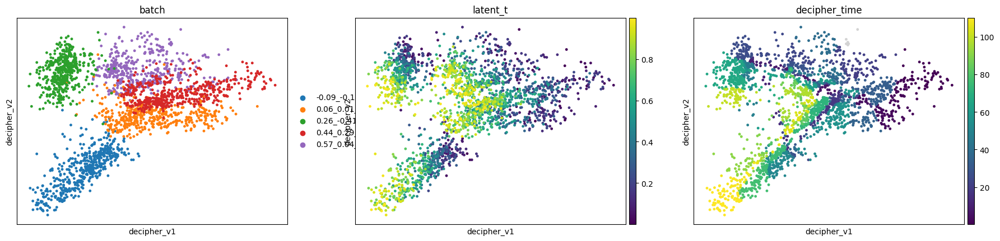

Decipher-VZ2-Add, sigma=0.5, seed=0, rho = 0.5399


/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


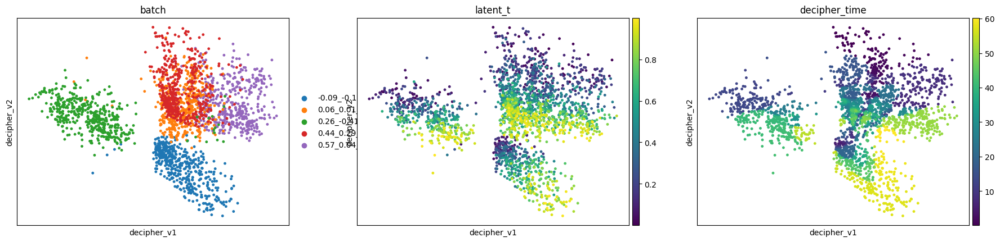

Decipher-MF-Add, sigma=0.5, seed=0, rho = 0.6461


/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


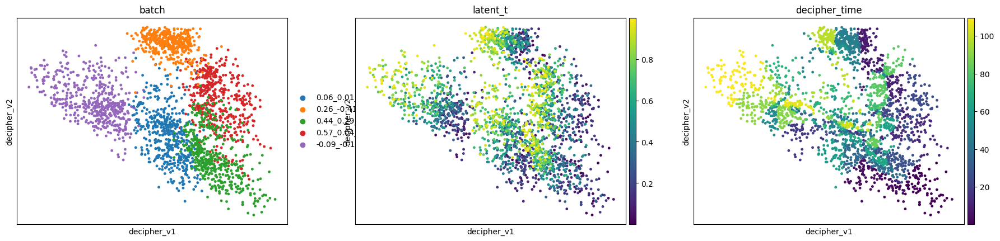

Base Decipher, sigma=0.5, seed=0, rho = 0.4593


In [21]:
plot_v_space(0.5)

### Sigma = 0.75

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


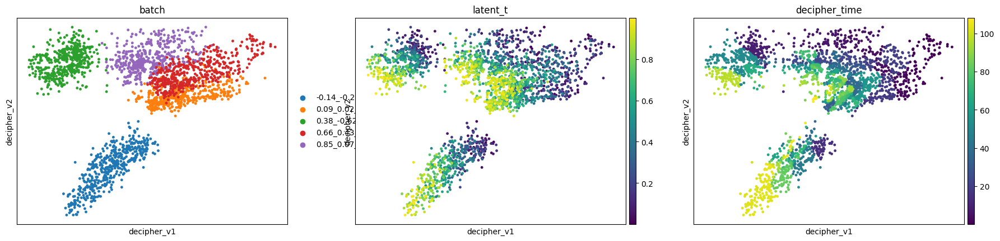

Decipher-VZ-Add, sigma=0.75, seed=0, rho = 0.6600


/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


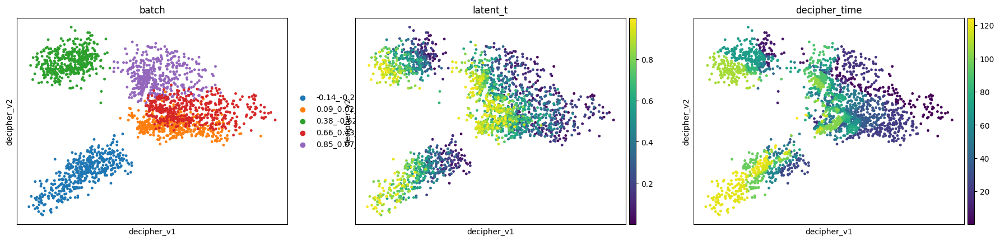

Decipher-VZ2-Add, sigma=0.75, seed=0, rho = 0.5841


/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


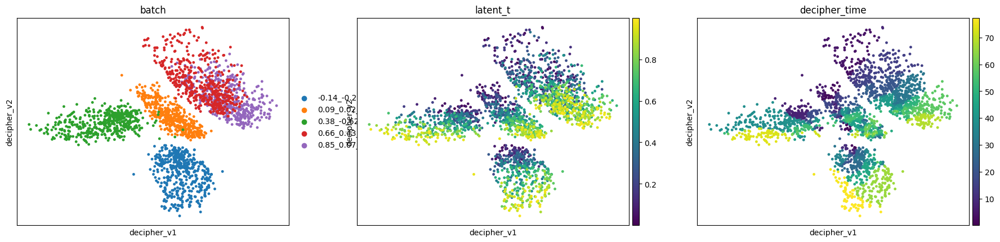

Decipher-MF-Add, sigma=0.75, seed=0, rho = 0.6807


/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


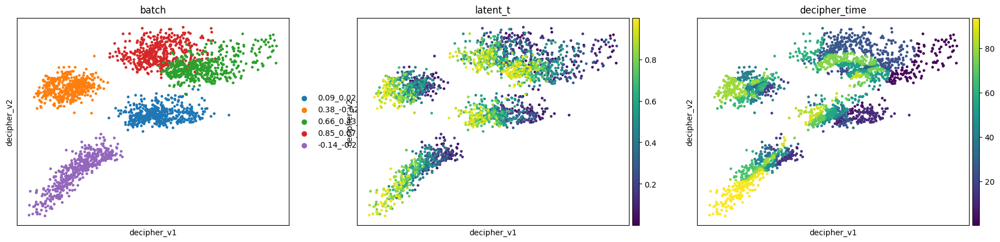

Base Decipher, sigma=0.75, seed=0, rho = 0.5379


In [22]:
plot_v_space(0.75)

### Sigma = 1.0

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


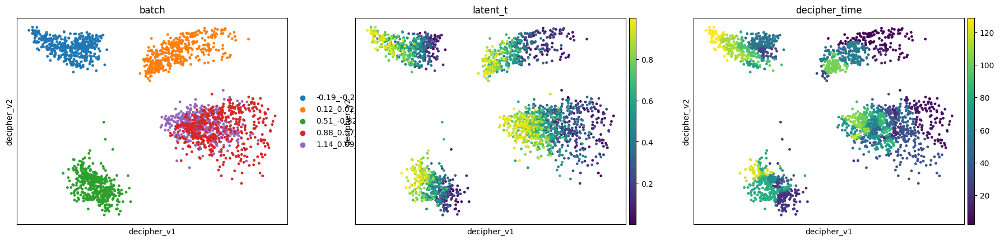

Decipher-VZ-Add, sigma=1.0, seed=0, rho = 0.6262


/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


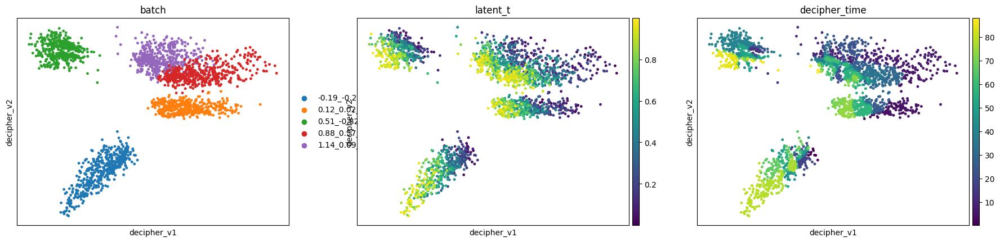

Decipher-VZ2-Add, sigma=1.0, seed=0, rho = 0.5886


/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


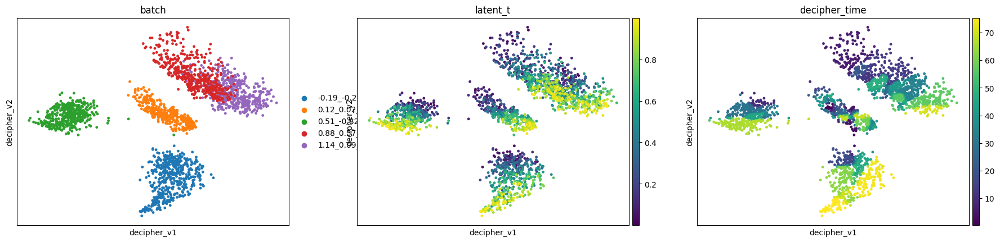

Decipher-MF-Add, sigma=1.0, seed=0, rho = 0.5615


/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


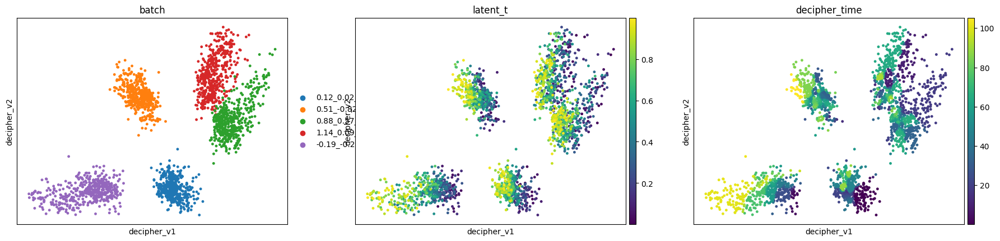

Base Decipher, sigma=1.0, seed=0, rho = 0.4612


In [23]:
plot_v_space(1.0)

### Sigma = 2.0

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


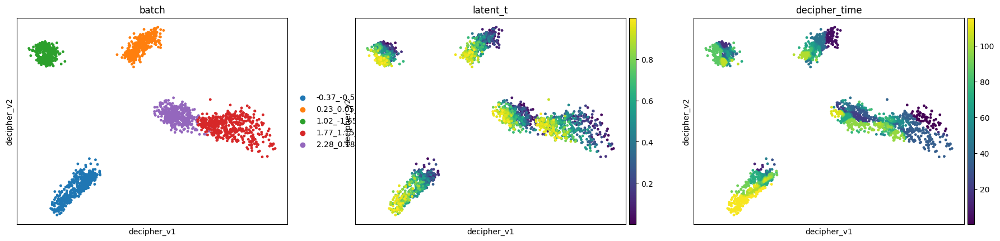

Decipher-VZ-Add, sigma=2.0, seed=0, rho = 0.5512


/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


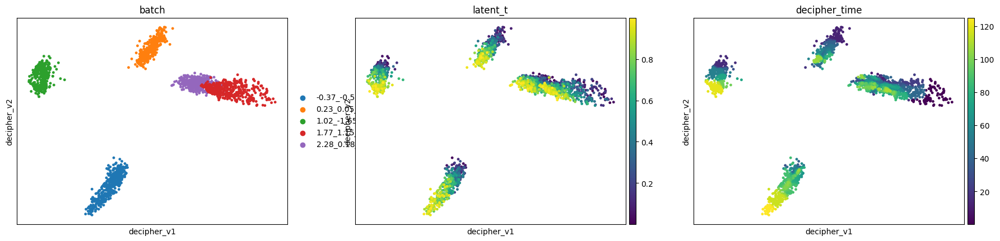

Decipher-VZ2-Add, sigma=2.0, seed=0, rho = 0.6275


/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


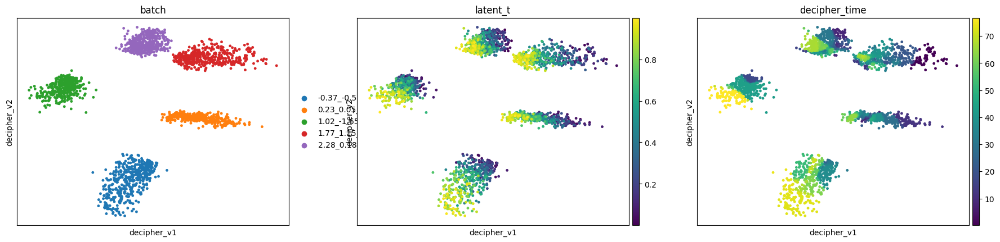

Decipher-MF-Add, sigma=2.0, seed=0, rho = 0.6110


/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


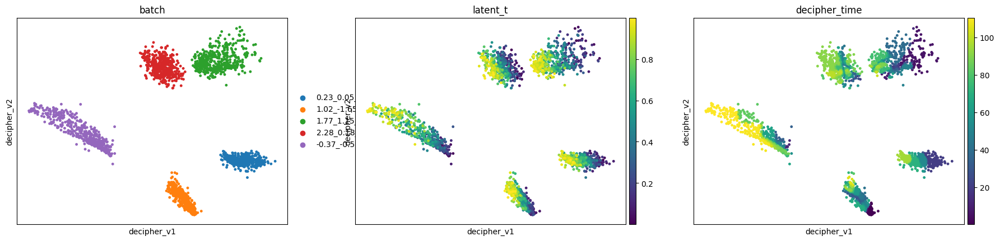

Base Decipher, sigma=2.0, seed=0, rho = 0.5230


In [24]:
plot_v_space(2.0)

### Sigma = 5.0

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


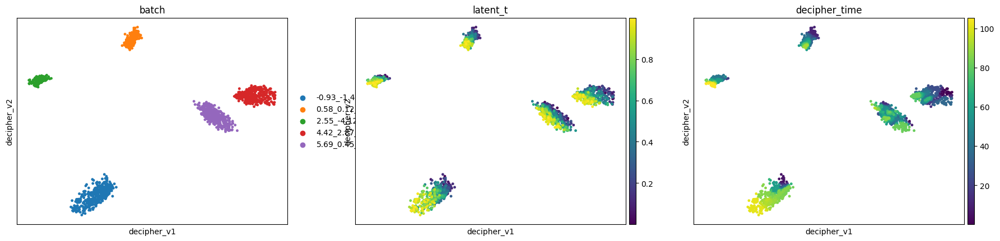

Decipher-VZ-Add, sigma=5.0, seed=0, rho = 0.5416


/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


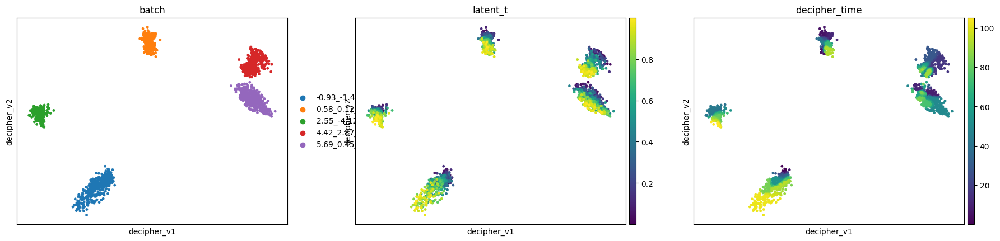

Decipher-VZ2-Add, sigma=5.0, seed=0, rho = 0.5669


/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


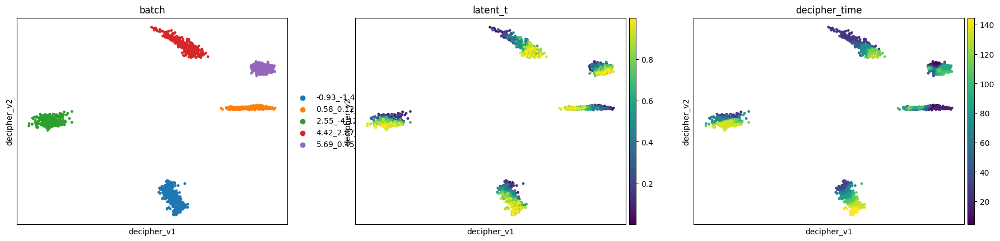

Decipher-MF-Add, sigma=5.0, seed=0, rho = 0.6634


/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


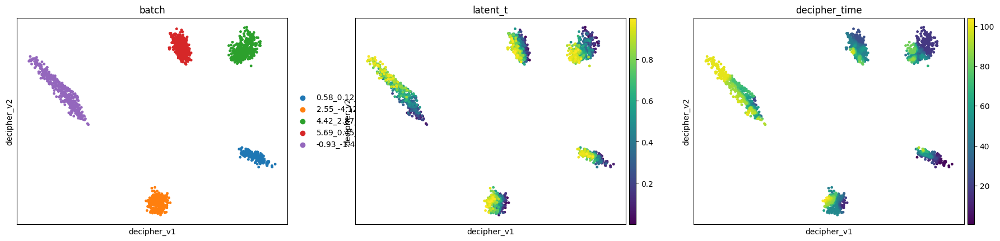

Base Decipher, sigma=5.0, seed=0, rho = 0.4743


In [25]:
plot_v_space(5.0)

## X-space: colored by batch

In [26]:
def plot_x_space(shift_sigma, seed=seed_for_detail, use_umap=False, n_pcs=20):
    for model_name in model_names:
        row, adata = load_run(run_log_df, shift_sigma, model_name, seed=seed)

        sc.pp.pca(adata, n_comps=min(n_pcs, adata.n_vars - 1), random_state=0)
        sc.pl.embedding(adata, basis="pca", color="batch",
                         title=f"{model_name}, sigma={shift_sigma}, X-space PCA")

        if use_umap:
            sc.pp.neighbors(adata, use_rep="X_pca", random_state=42)
            sc.tl.umap(adata, random_state=42)
            sc.pl.embedding(adata, basis="umap", color="batch",
                             title=f"{model_name}, sigma={shift_sigma}, X-space UMAP")

### Sigma = 0.1

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


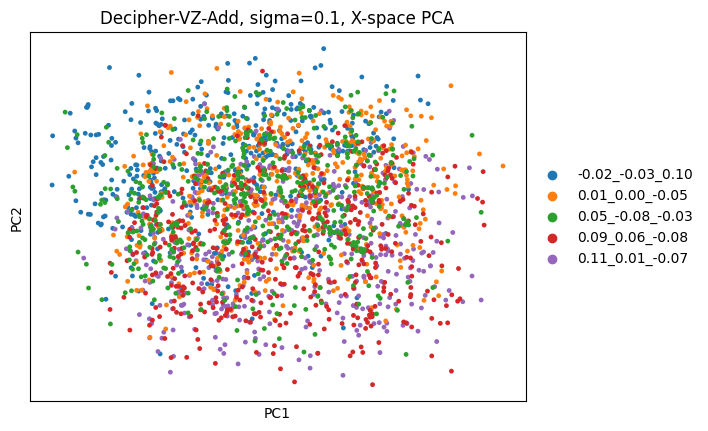

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


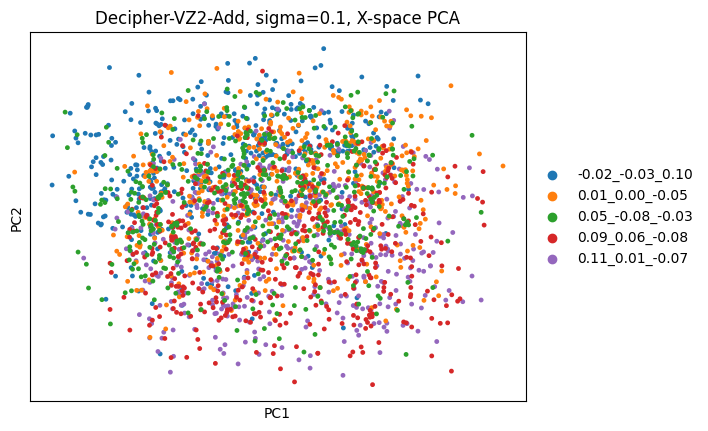

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


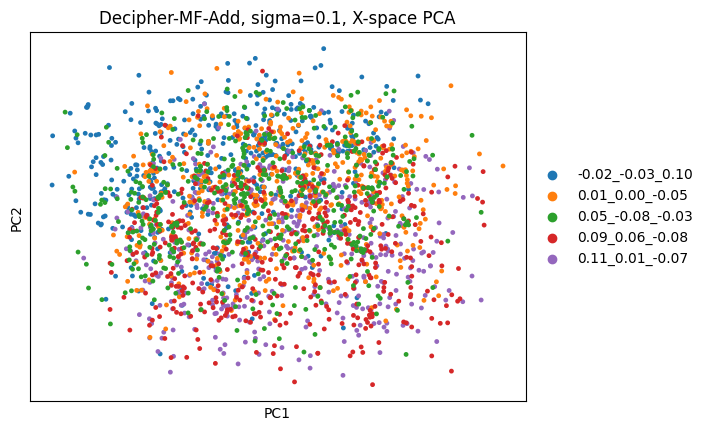

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


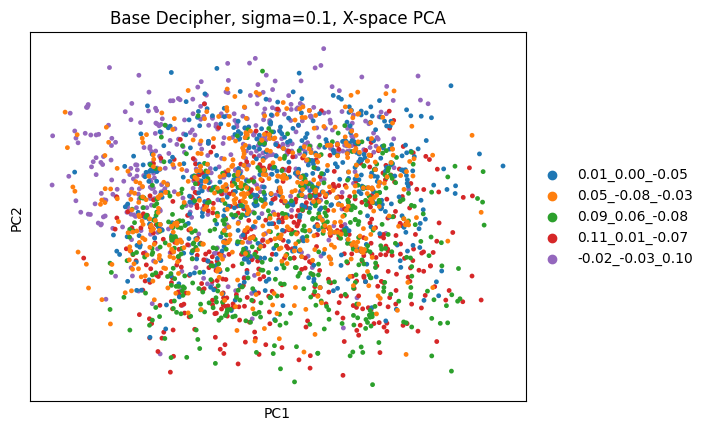

In [27]:
plot_x_space(0.1)

### Sigma = 0.25

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


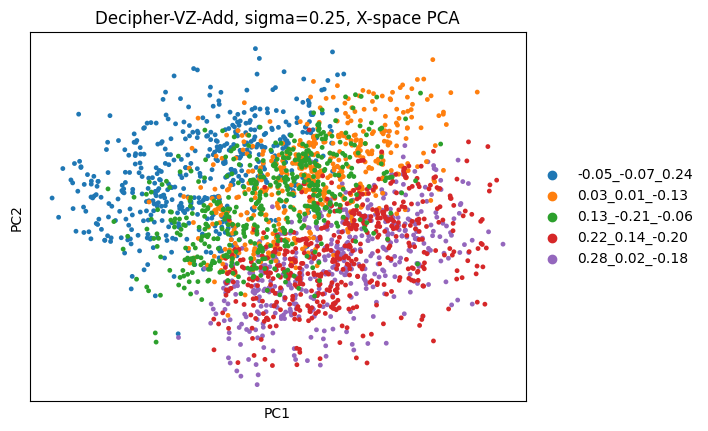

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


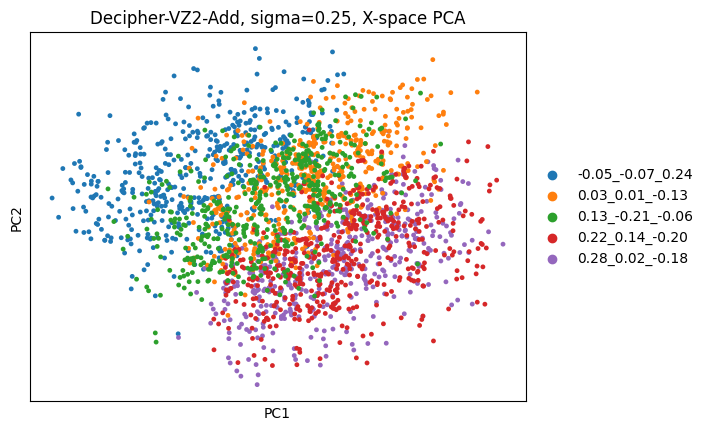

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


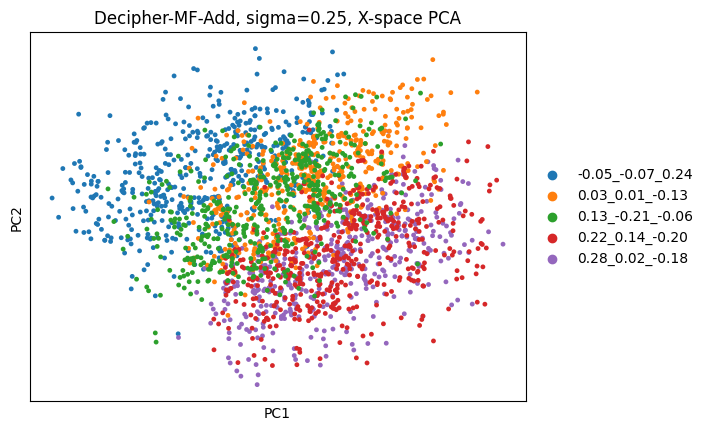

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


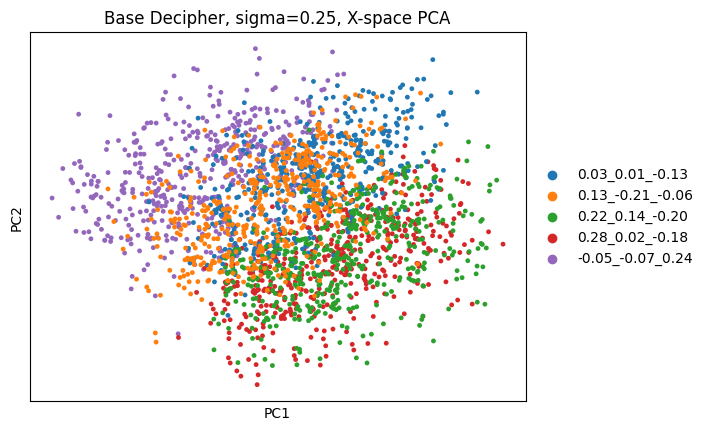

In [28]:
plot_x_space(0.25)

### Sigma = 0.5

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


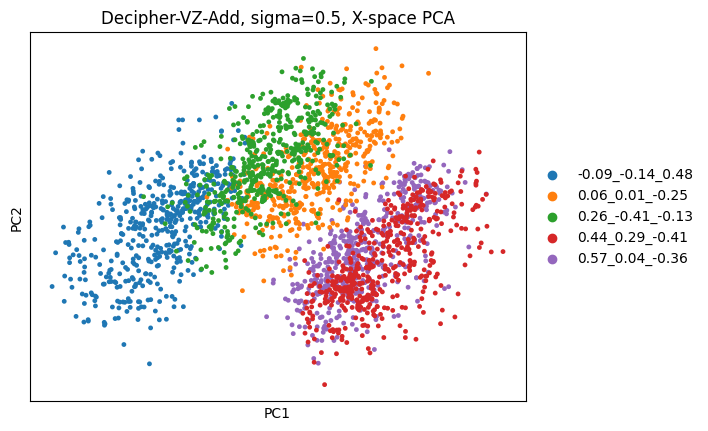

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


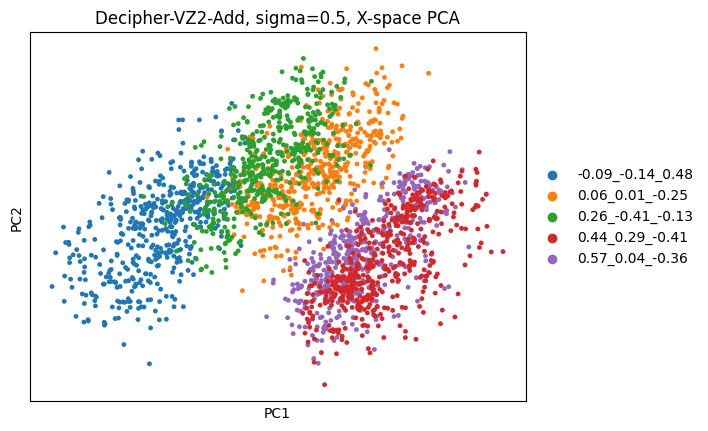

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


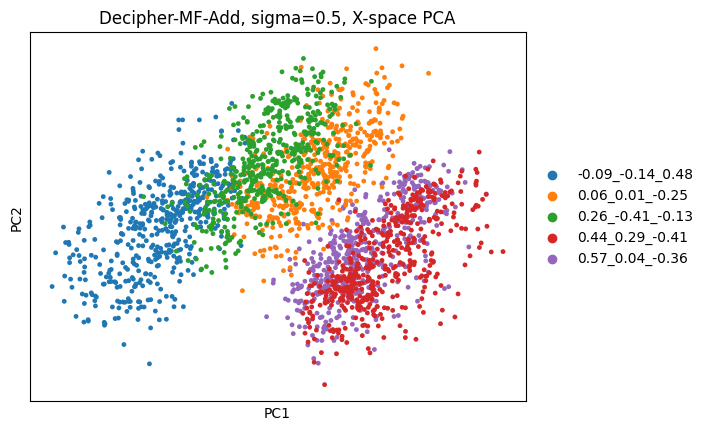

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


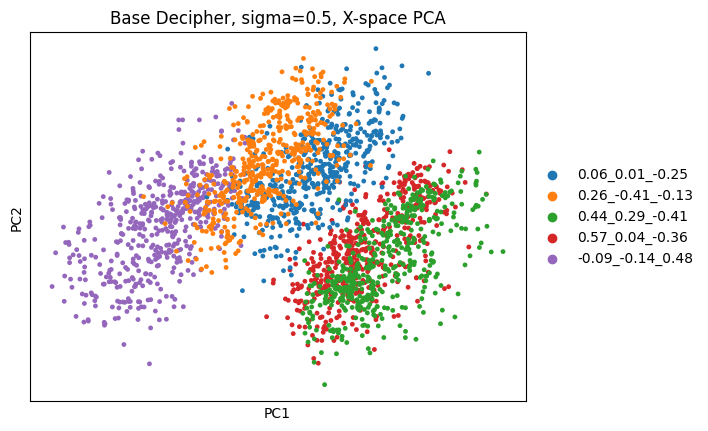

In [29]:
plot_x_space(0.5)

### Sigma = 0.75

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


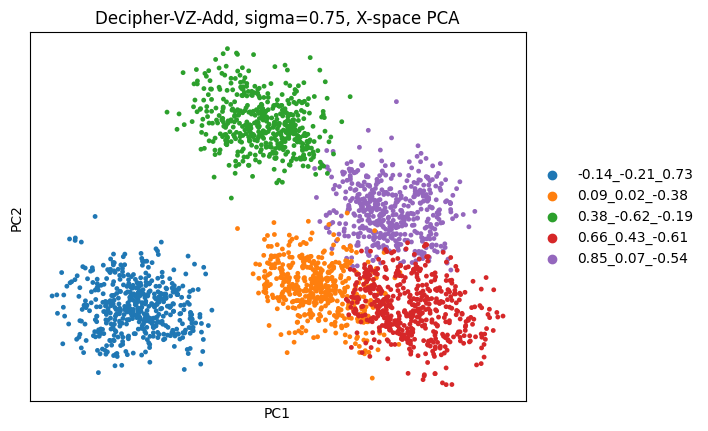

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


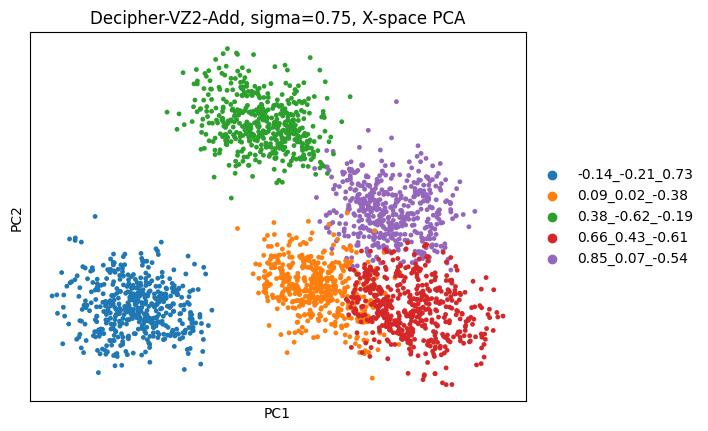

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


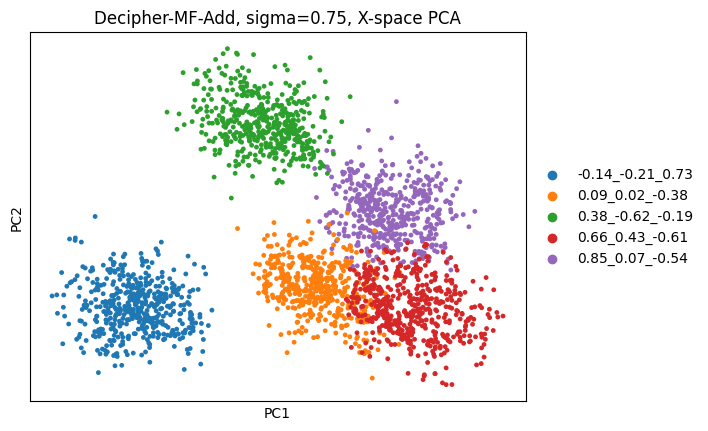

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


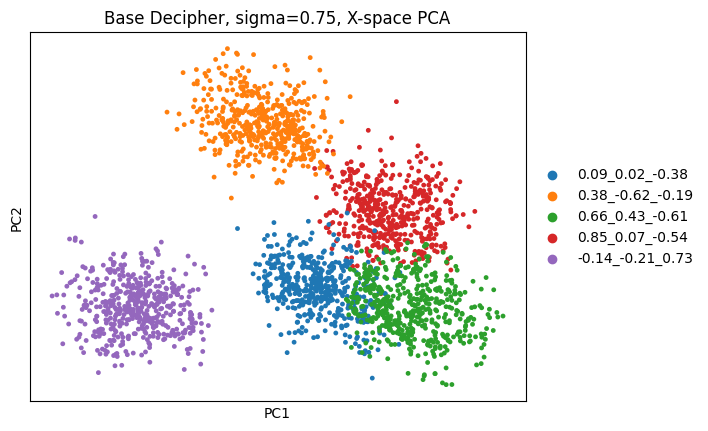

In [30]:
plot_x_space(0.75)

### Sigma = 1.0

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


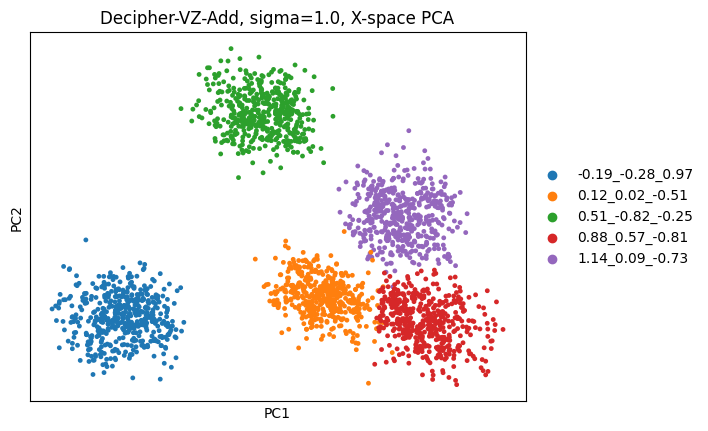

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


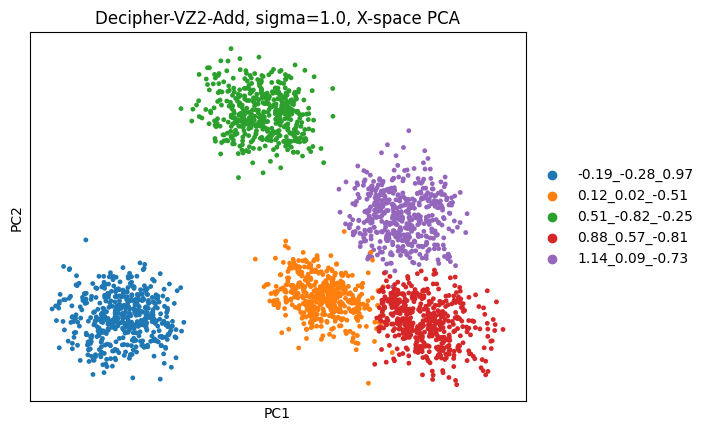

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


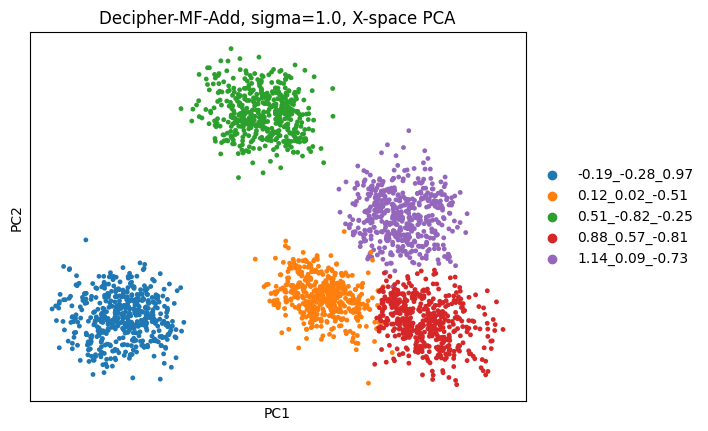

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


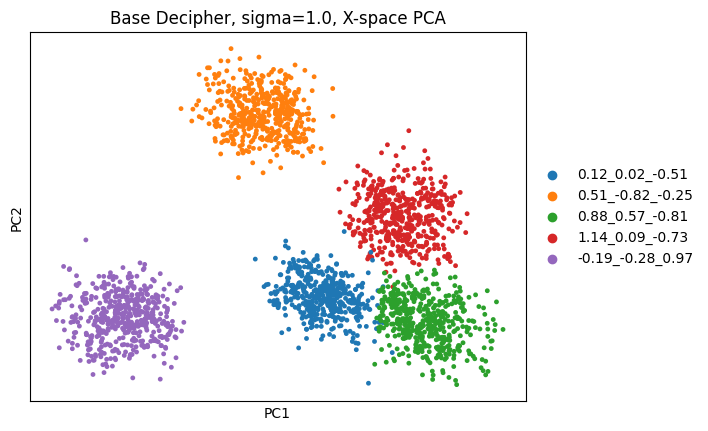

In [31]:
plot_x_space(1.0)

### Sigma = 2.0

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


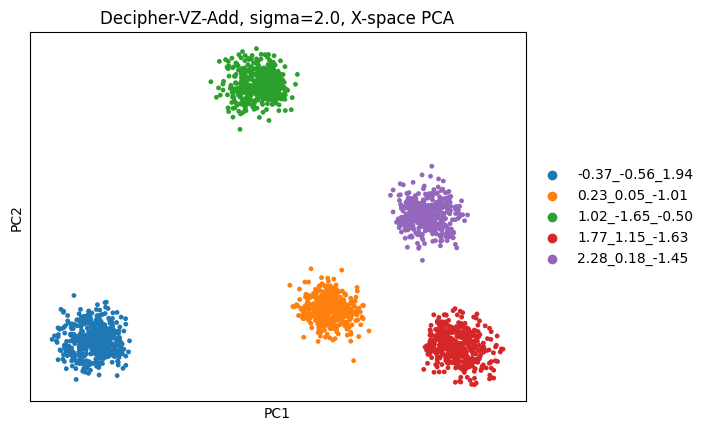

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


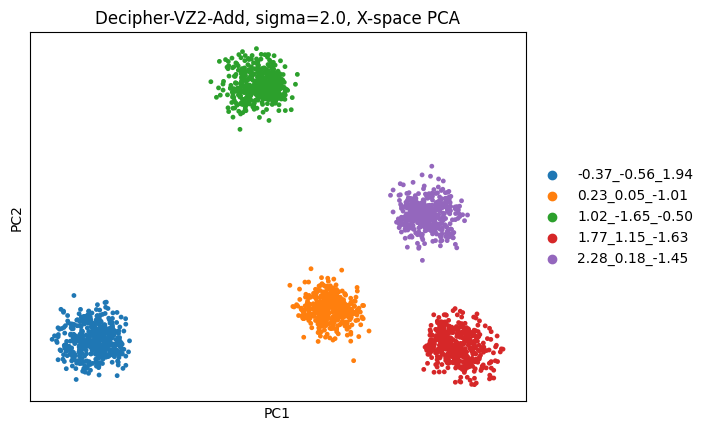

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


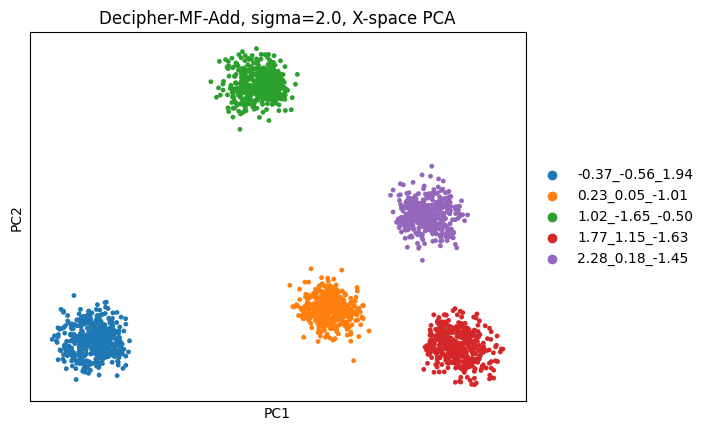

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


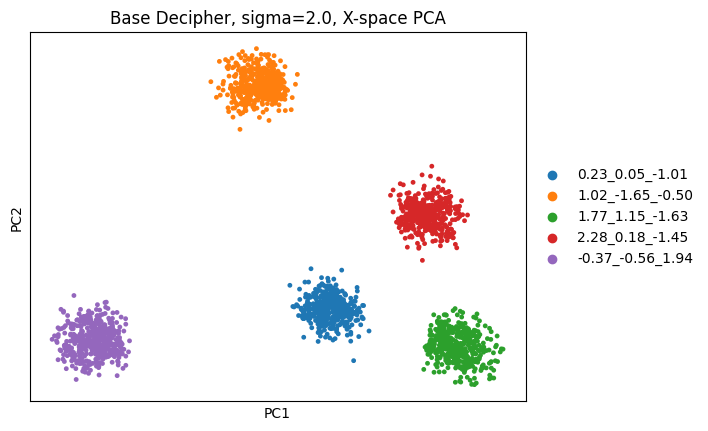

In [32]:
plot_x_space(2.0)

### Sigma = 5.0

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


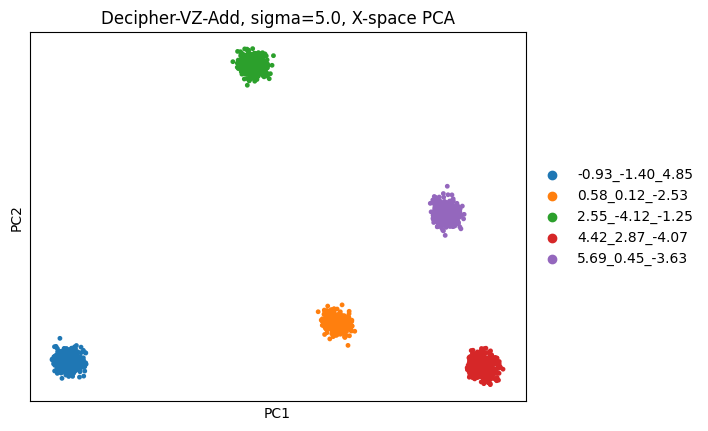

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


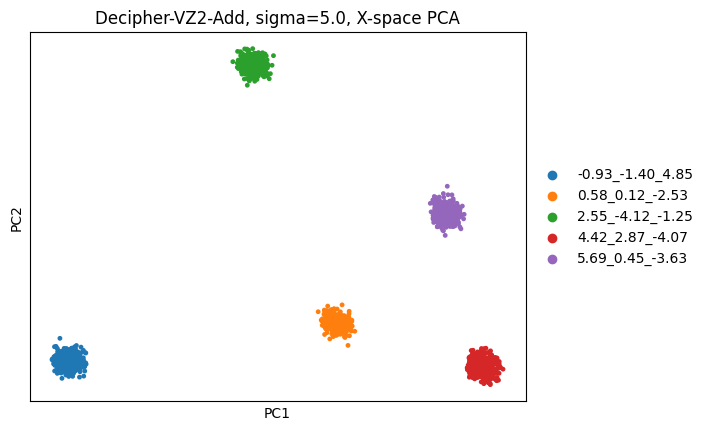

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


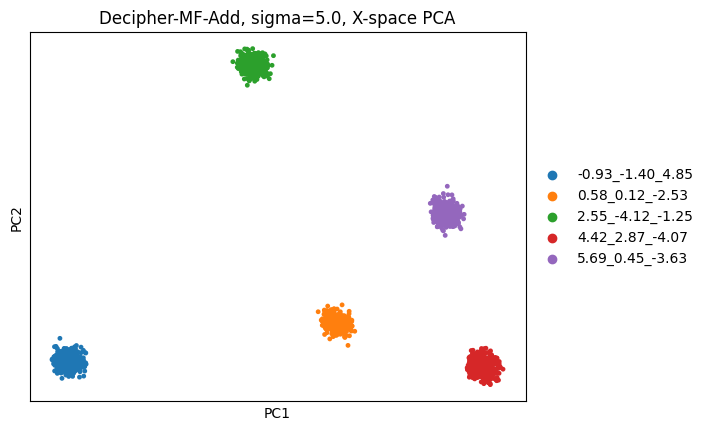

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


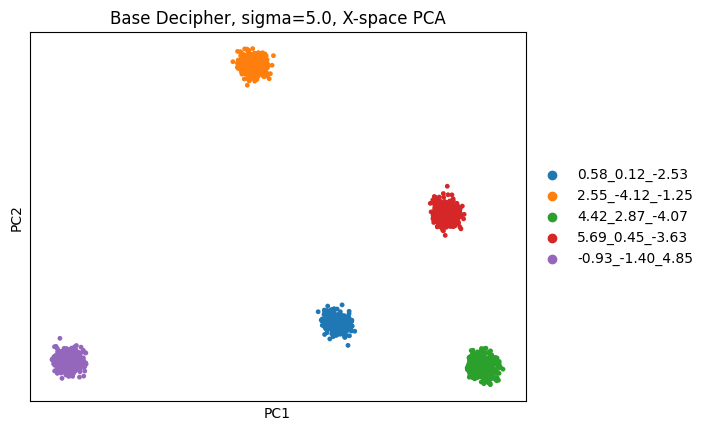

In [33]:
plot_x_space(5.0)